# Gegenfaktische Erklärungen mit DiCE
## Einfluss festgehaltener Merkmale und zulässiger Wertebereiche

Wahlfach Explainable AI, DHBW Stuttgart · Autor: Damian Schmidt (4246980) inf24081@lehre.dhbw-stuttgart.de

**Forschungsfrage:** Wie beeinflussen festgehaltene Merkmale und begrenzte Wertebereiche die Erfolgsrate und den Änderungsumfang gegenfaktischer Erklärungen?

| Baustein | Rolle |
|---|---|
| Random Forest | Lernt aus Eingabemerkmalen die Kreditrisikoklasse |
| DiCE | Sucht alternative Eingaben mit einer anderen Modellvorhersage |
| Kontrollierter Vergleich | Gleiches Modell, gleiche Fälle und Suchseeds, unterschiedliche Änderungsregeln |

Installation und Ausführung beschreibt die `README.md`.

Das Notebook hat genau eine feste Konfiguration (Abschnitt 2); alle drei Versuchsreihen (Abschnitt 8) werden bei jedem Lauf vollständig ausgeführt. R0 ist vorab festgelegt; R1 und R2 wurden nach dem ersten Lauf ergänzt und sind explorativ.

### 1. Python-Pakete

Wir benötigen pandas und NumPy für Tabellen, scikit-learn für den Random Forest, DiCE für die Erklärungen und Matplotlib für Abbildungen. DiCE wird über sein scikit-learn-Backend genutzt. Die Paketversionen legt `requirements.txt` fest.

In [1]:
import contextlib
import io
import json
import math
import platform
import random
import time
import warnings
from importlib import metadata
from pathlib import Path

import dice_ml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from raiutils.exceptions import UserConfigValidationException
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix, f1_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import plot_tree

### 2. Einstellungen

Die drei Bedingungen werden vor dem Vergleich definiert. Der Random Forest bleibt anschließend unverändert. Es gibt genau eine Versuchskonfiguration, die für alle drei Versuchsreihen gilt:

- Erklärt werden alle Testfälle, die der Forest als hohes Risiko (bad / 1) vorhersagt.
- Drei Versuchsreihen (Abschnitt 8) mit jeweils den Bedingungen A, B und C. R0 ist vorab festgelegt; R1 und R2 wurden nach dem ersten Lauf ergänzt und sind explorativ.
- Jede Kombination aus Versuchsreihe, Fall und Bedingung wird mit 5 Suchseeds wiederholt.
- Festes Suchbudget: höchstens 20.000 Kandidatenzeilen je Suche.
- Je Suche werden bis zu 3 unterschiedliche Alternativen angefordert.
- Primärer Erfolg: mindestens eine unabhängig bestätigte, regelkonforme Alternative.
- Ergänzend: Erfolg mit einer Alternative, die höchstens ein Merkmal ändert.
- Das maximale Suchbudget ist vergleichbar; erfolgreiche Suchen können früher enden. Tatsächliche Modellabfragen werden zusätzlich gezählt.

DiCEs Zufallssuche wird verwendet, weil ihre Stichprobengröße und ihre Modellabfragen gut nachvollziehbar sind. Eine zusätzliche nachträgliche Sparsifizierung ist deaktiviert, damit sie das Suchbudget und die Regeln nicht unbemerkt verändert. Die gefundenen Änderungen sind Suchergebnisse, keine garantiert global minimalen Änderungen.

In [2]:
DATA_FOLDER = Path.cwd() / "statlog+german+credit+data"
SPLIT_SEED = 42
RANDOM_FOREST_SEED = 42
BOOTSTRAP_SEED = 2026
SEARCH_SEEDS = [11, 29, 47, 71, 101]
TARGET_CLASS = 0
NUM_CFS = 3
NUM_TREES = 120
RELATIVE_LIMIT = 0.20
CANDIDATE_BUDGET = 20000

MODEL_ROW_LIMIT = CANDIDATE_BUDGET + 50
BOOTSTRAP_REPETITIONS = 2000
RESULTS_FOLDER = Path.cwd() / "ergebnisse_dice"
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

### 3. Originaldaten und Herkunft

Verwendet wird **german.data**, die Originalversion mit 20 Eingabemerkmalen, keine bereits anders kodierte numerische Ersatzversion.

Quelle: Hans Hofmann (1994), *Statlog (German Credit Data)*, UCI Machine Learning Repository. DOI: https://doi.org/10.24432/C5NC77. Die unveränderten Originaldaten werden aus dem lokalen Ordner `statlog+german+credit+data` (Datei `german.data`) neben diesem Notebook gelesen. Damit kann die Analyse nach der Paketinstallation ohne Internetverbindung ausgeführt werden.

Die ursprünglichen Kategorien A11, A12 usw. bleiben als Kategorien erhalten. Es werden keine Euro-Einheiten oder heutigen wirtschaftlichen Verhältnisse unterstellt. Die Zielwerte 1/2 werden im Notebook ausdrücklich auf 0/1 abgebildet.

In [3]:
DATA_FILE = DATA_FOLDER / "german.data"

if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Datendatei nicht gefunden: {DATA_FILE}\n"
        "Den Ordner statlog+german+credit+data mit german.data neben dieses Notebook legen oder DATA_FOLDER in den Einstellungen anpassen."
    )

original_bytes = DATA_FILE.read_bytes()

FEATURES = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount", "savings_status", "employment", "installment_rate", "personal_status_sex", "other_debtors", "residence_since", "property", "age", "other_installment_plans", "housing", 
    "existing_credits", "job", "dependents", "telephone", "foreign_worker",
]

NUMERICAL = [
    "duration", "credit_amount", "installment_rate", "residence_since", "age", "existing_credits", "dependents",
]

CATEGORICAL = [m for m in FEATURES if m not in NUMERICAL]
TARGET = "risk"
CLASS_NAMES = {0: "good", 1: "bad"}

df = pd.read_csv(io.BytesIO(original_bytes), sep=r"\s+", header=None, names=FEATURES + ["original_class"])

for m in NUMERICAL:
    df[m] = pd.to_numeric(df[m], errors="raise").astype(int)
for m in CATEGORICAL:
    df[m] = df[m].astype(str)

assert set(df["original_class"].unique()) == {1, 2}

df[TARGET] = df.pop("original_class").map({1: 0, 2: 1}).astype(int)
df.index.name = "case_id"

assert df.shape == (1000, 21)
assert not df.isna().any().any()

print(f"{len(df)} Fälle, {len(FEATURES)} Eingabemerkmale, eine Zielvariable.")
print("Kodierung: ursprünglich 1 -> jetzt 0 (good); ursprünglich 2 -> jetzt 1 (bad).")
display(df.head())

1000 Fälle, 20 Eingabemerkmale, eine Zielvariable.
Kodierung: ursprünglich 1 -> jetzt 0 (good); ursprünglich 2 -> jetzt 1 (bad).


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,risk
case_id,,,,,,,,,,,,,,,,,,,,,
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


### 4. Die Spalten verstehen

X enthält die Eingaben. y ist die bekannte Antwort, die beim Training gelernt werden soll. Die Zielvariable wird niemals als Eingabemerkmal verwendet. Ein einzelner Fall besitzt 20 Angaben; nicht 20 unabhängige Trainingsfälle.

Die Dokumentation der Originalkategorien ist über die UCI-Seite erreichbar. Besonders wichtig: Geschlecht und Personenstand sind in einer gemeinsamen Kategorie zusammengefasst. Das Notebook trennt diese Angaben nicht künstlich.

,Merkmal,Bedeutung,Typ
0,checking_status,Status des bestehenden Girokontos (Kategorien ...,kategorial
1,duration,Kreditlaufzeit in Monaten,numerisch
2,credit_history,Bisherige Kredithistorie (Kategorien),kategorial
3,purpose,Verwendungszweck des Kredits,kategorial
4,credit_amount,Kreditbetrag in den Originaleinheiten des Date...,numerisch
5,savings_status,Kategorie der Ersparnisse,kategorial
6,employment,Kategorie der bisherigen Beschäftigungsdauer,kategorial
7,installment_rate,Dokumentierte Stufe der Ratenbelastung,numerisch
8,personal_status_sex,Gemeinsame Kategorie für Personenstand und Ges...,kategorial
9,other_debtors,Weitere Schuldner oder Bürgen,kategorial


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,20.90,3271.26,2.97,2.84,35.55,1.41,1.16
std,12.06,2822.74,1.12,1.10,11.38,0.58,0.36
min,4.00,250.00,1.00,1.00,19.00,1.00,1.00
25%,12.00,1365.50,2.00,2.00,27.00,1.00,1.00
50%,18.00,2319.50,3.00,3.00,33.00,1.00,1.00
75%,24.00,3972.25,4.00,4.00,42.00,2.00,1.00
max,72.00,18424.00,4.00,4.00,75.00,4.00,2.00


,Fälle
risk,
good,700
bad,300


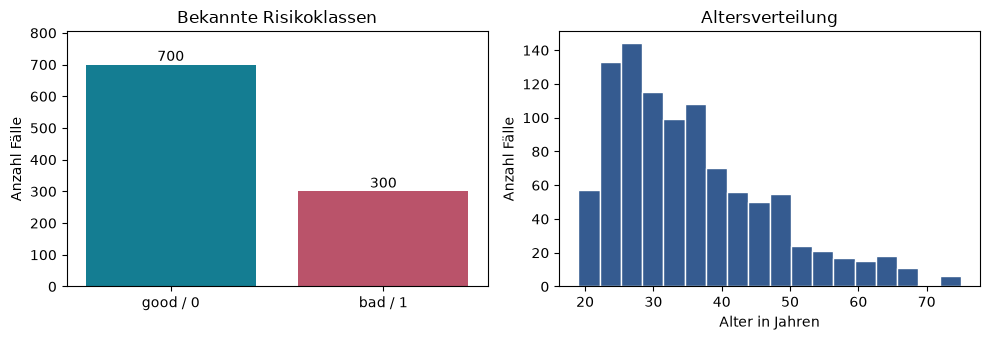

In [4]:
DESCRIPTIONS = {
    "checking_status": "Status des bestehenden Girokontos (Kategorien A11-A14)",
    "duration": "Kreditlaufzeit in Monaten",
    "credit_history": "Bisherige Kredithistorie (Kategorien)",
    "purpose": "Verwendungszweck des Kredits",
    "credit_amount": "Kreditbetrag in den Originaleinheiten des Datensatzes",
    "savings_status": "Kategorie der Ersparnisse",
    "employment": "Kategorie der bisherigen Beschäftigungsdauer",
    "installment_rate": "Dokumentierte Stufe der Ratenbelastung",
    "personal_status_sex": "Gemeinsame Kategorie für Personenstand und Geschlecht",
    "other_debtors": "Weitere Schuldner oder Bürgen",
    "residence_since": "Dokumentierte Dauer am bisherigen Wohnort",
    "property": "Kategorie des Vermögens / Eigentums",
    "age": "Alter in Jahren",
    "other_installment_plans": "Andere Ratenzahlungspläne",
    "housing": "Wohnsituation",
    "existing_credits": "Anzahl bestehender Kredite bei dieser Bank",
    "job": "Berufskategorie",
    "dependents": "Anzahl unterhaltsberechtigter Personen",
    "telephone": "Telefonkategorie",
    "foreign_worker": "Im historischen Datensatz erfasste Kategorie foreign worker",
}

feature_glossary = pd.DataFrame({
    "Merkmal": FEATURES,
    "Bedeutung": [DESCRIPTIONS[m] for m in FEATURES],
    "Typ": ["numerisch" if m in NUMERICAL else "kategorial" for m in FEATURES],
})

display(feature_glossary)
display(df[NUMERICAL].describe().round(2))
display(df[TARGET].value_counts().sort_index().rename(index=CLASS_NAMES).to_frame("Fälle"))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
counts = df[TARGET].value_counts().sort_index()

ax[0].bar(["good / 0", "bad / 1"], counts.values, color=["#147d92", "#ba536a"])
ax[0].set(title="Bekannte Risikoklassen", ylabel="Anzahl Fälle")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 12, str(v), ha="center")
ax[0].set_ylim(0, counts.max() * 1.15)

ax[1].hist(df["age"], bins=18, color="#355b90", edgecolor="white")
ax[1].set(title="Altersverteilung", xlabel="Alter in Jahren", ylabel="Anzahl Fälle")

fig.tight_layout()
fig.savefig(RESULTS_FOLDER / "01_datenueberblick.png")
plt.show()

### 5. Training und Test sauber trennen

80 % der Fälle werden Trainingsdaten, 20 % Testdaten. Die stratifizierte Aufteilung bewahrt die Klassenanteile. Der Zufallsstart ist festgehalten.

Alle Vorverarbeitungsschritte und der Forest werden nur auf den Trainingsdaten angepasst. Die Kreuzvalidierung findet ebenfalls ausschließlich dort statt. Es gibt keine Optimierung anhand der späteren Test- oder DiCE-Ergebnisse.

In [5]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SPLIT_SEED, stratify=y)

assert set(X_train.index).isdisjoint(X_test.index)
assert TARGET not in X_train.columns

display(pd.DataFrame({
    "Daten": ["Training", "Test"],
    "Fälle": [len(X_train), len(X_test)],
    "good / 0": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "bad / 1": [int((y_train == 1).sum()), int((y_test == 1).sum())],
}))

,Daten,Fälle,good / 0,bad / 1
0,Training,800,560,240
1,Test,200,140,60


### 6. Random Forest trainieren

Ein Entscheidungsbaum verwendet aufeinanderfolgende Trennregeln. Ein Random Forest kombiniert viele Bäume, die mit verschiedenen Stichproben und Merkmalsauswahlen aufgebaut werden (Breiman 2001).

One-Hot-Encoding gibt jeder Kategorie eine eigene Zahlenspalte. Die ursprünglichen 20 Merkmale bleiben für DiCE und die Erklärung erhalten; die zusätzlichen Spalten existieren nur innerhalb der Modellpipeline.

Die Einstellungen sind eine einfache, vorab festgelegte Ausgangsbasis. Balanced Accuracy und der Recall für Klasse 1 ergänzen die gewöhnliche Accuracy, weil die Klassen unterschiedlich häufig vorkommen.

In [6]:
preprocessing = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("numerical", "passthrough", NUMERICAL),
    ],
    remainder="drop",
)

model = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestClassifier(n_estimators=NUM_TREES, max_depth=8, min_samples_leaf=3, random_state=RANDOM_FOREST_SEED, n_jobs=1)),
])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SPLIT_SEED)
cv_results = cross_validate(
    model, X_train, y_train, cv=cv, n_jobs=1, 
    scoring={"balanced_accuracy": "balanced_accuracy", "f1_macro": "f1_macro", "recall_bad": "recall"},
)
cv_table = pd.DataFrame({
    "Metrik": ["Balanced Accuracy", "F1 macro", "Recall bad / 1"],
    "CV-Mittel": [cv_results["test_" + m].mean() for m in ("balanced_accuracy", "f1_macro", "recall_bad")],
    "CV-Standardabweichung": [cv_results["test_" + m].std(ddof=1) for m in ("balanced_accuracy", "f1_macro", "recall_bad")],
})

display(cv_table.round(3))
model.fit(X_train, y_train)
print("Forest auf allen 800 Trainingsfällen angepasst.")

,Metrik,CV-Mittel,CV-Standardabweichung
0,Balanced Accuracy,0.599,0.027
1,F1 macro,0.599,0.035
2,Recall bad / 1,0.242,0.038


Forest auf allen 800 Trainingsfällen angepasst.


,Modell,Accuracy,Balanced Accuracy,F1 macro,Recall bad / 1
0,Häufigste Klasse,0.700,0.500,0.412,0.000
1,Random Forest,0.775,0.658,0.675,0.367


,precision,recall,f1-score,support
good / 0,0.778,0.950,0.855,140.000
bad / 1,0.759,0.367,0.494,60.000
accuracy,0.775,0.775,0.775,0.775
macro avg,0.768,0.658,0.675,200.000
weighted avg,0.772,0.775,0.747,200.000


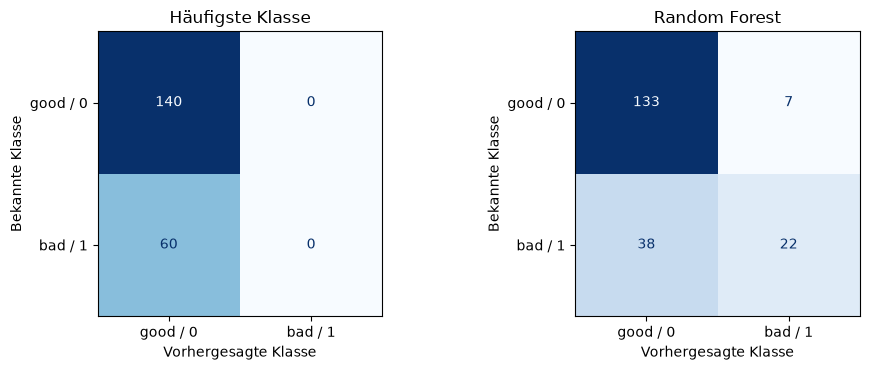

In [7]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
test_predictions = model.predict(X_test)

def evaluate_classifier(name, pred):
    return {
        "Modell": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "Recall bad / 1": recall_score(y_test, pred, pos_label=1, zero_division=0),
    }

model_comparison = pd.DataFrame([
    evaluate_classifier("Häufigste Klasse", dummy.predict(X_test)),
    evaluate_classifier("Random Forest", test_predictions),
])

display(model_comparison.round(3))
display(pd.DataFrame(classification_report(y_test, test_predictions, target_names=["good / 0", "bad / 1"], output_dict=True, zero_division=0)).T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, name, pred in zip(ax, ["Häufigste Klasse", "Random Forest"], [dummy.predict(X_test), test_predictions]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),  display_labels=["good / 0", "bad / 1"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set(title=name, xlabel="Vorhergesagte Klasse", ylabel="Bekannte Klasse")

fig.tight_layout()
fig.savefig(RESULTS_FOLDER / "02_confusion_matrices.png")
plt.show()

**Einordnung:** Der Forest ist besser als die Baseline „Häufigste Klasse“ (Accuracy 77,5 % statt 70,0 %, Balanced Accuracy 65,8 % statt 50,0 %), erkennt aber nur 36,7 % der bekannten bad-Fälle im Testset; in der Kreuzvalidierung sind es 24,2 %. Er sagt bad also selten voraus. Für die Erklärungen ist das wichtig: DiCE erklärt nur die wenigen Fälle, die der Forest als bad einstuft (Abschnitt 9), und diese liegen knapp an der Entscheidungsgrenze. Eine hohe Erfolgsrate der Erklärungen sagt deshalb nichts über die Güte des Modells aus.

#### Ein einzelner Baum aus dem Forest

Der Forest besteht aus 120 Entscheidungsbäumen. Jeder Baum wurde auf einer Bootstrap-Stichprobe der Trainingsdaten und mit zufälliger Merkmalsauswahl je Trennung gelernt; die Vorhersage des Forests ist der Mittelwert der Klassenwahrscheinlichkeiten aller Bäume. Ein einzelner Baum zeigt deshalb nur anschaulich, *wie* die Entscheidungsregeln aussehen, nicht wie der gesamte Forest entscheidet.

Dargestellt sind die Wurzel und die drei folgenden Ebenen des ersten Baums (Knoten bis Tiefe 3; die Gesamttiefe steht im Titel, höchstens 8). Tiefere Teilbäume erscheinen als „(...)“. Jeder Knoten nennt die Trennregel, den Anteil der Bootstrap-Stichprobe im Knoten und die Klassenanteile `[good, bad]`; die Farbe zeigt die Mehrheitsklasse (orange = good, blau = bad; je kräftiger, desto eindeutiger). Bei One-Hot-Spalten bedeutet zum Beispiel `checking_status_A14 <= 0.5`: Die Kategorie A14 liegt **nicht** vor (linker Ast).

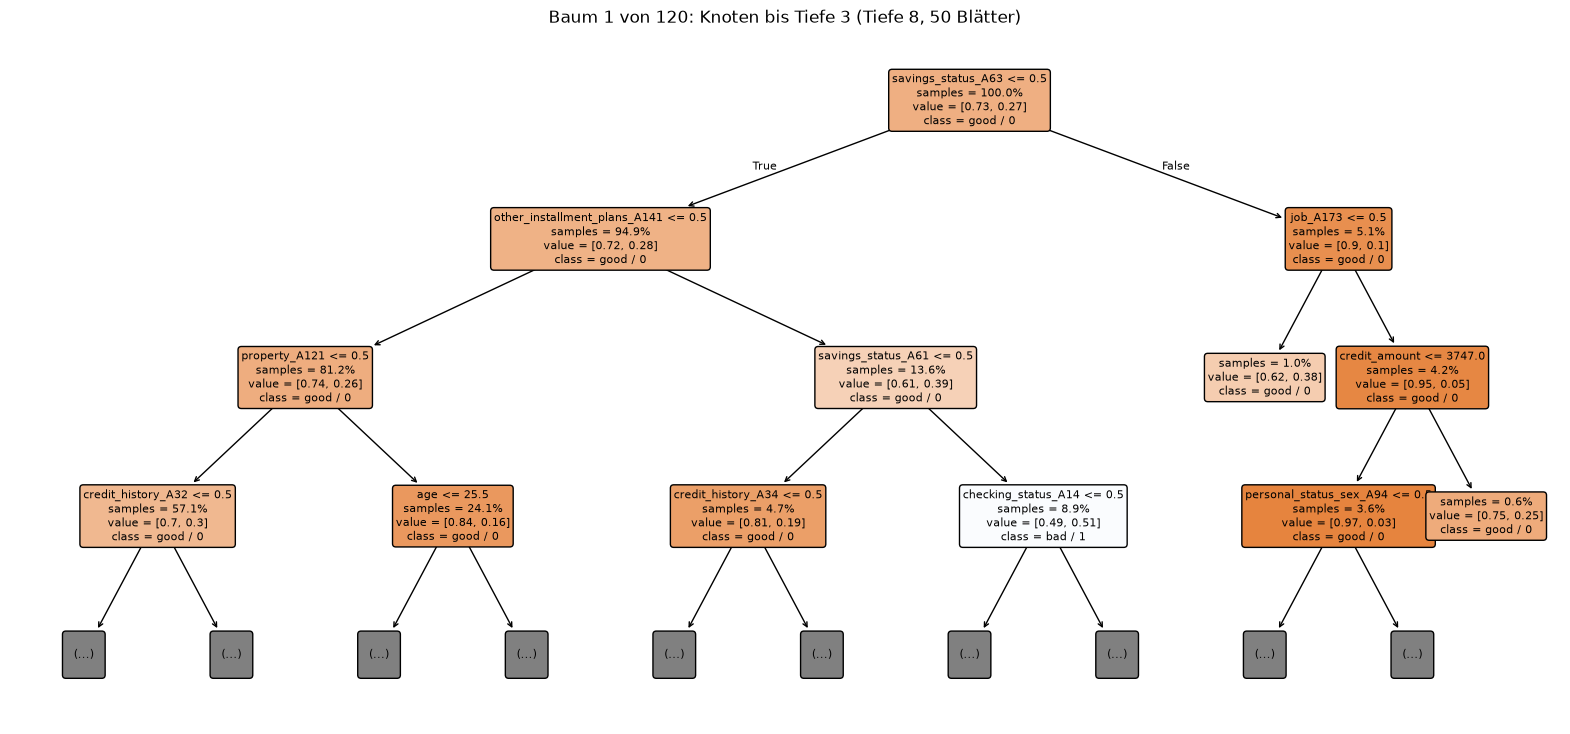

In [8]:
feature_names = [name.split("__", 1)[1] for name in model.named_steps["preprocessing"].get_feature_names_out()]
example_tree = model.named_steps["random_forest"].estimators_[0]

fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(example_tree, max_depth=3, feature_names=feature_names, class_names=["good / 0", "bad / 1"], filled=True, rounded=True, impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title(f"Baum 1 von {NUM_TREES}: Knoten bis Tiefe 3 (Tiefe {example_tree.get_depth()}, {example_tree.get_n_leaves()} Blätter)")
fig.savefig(RESULTS_FOLDER / "02b_beispielbaum.png")
plt.show()

### 7. DiCE: nach dem Training erklären

Eine gegenfaktische Erklärung beantwortet die Frage, welche Änderung der Eingabe die Vorhersage des Modells ändern würde (Wachter et al. 2018). DiCE erzeugt mehrere, möglichst unterschiedliche solcher Alternativen (Mothilal et al. 2020).

Für einen als bad / 1 vorhergesagten Fall sucht DiCE alternative Eingaben, für die der eingefrorene Forest good / 0 vorhersagt. Die bekannte Testklasse wird dabei nicht als Ziel verwendet: Erklärt wird die konkrete Modellentscheidung.

DiCEs Referenzdaten stammen ausschließlich aus dem Training. Das Suchverfahren kennt das Modell über seine Vorhersagefunktion. Der folgende kleine Wrapper zählt die ausgewerteten Eingabezeilen und setzt eine harte Obergrenze. Eine Zeile zählt als eine Modellabfrage, unabhängig von der Bündelung in Python-Funktionsaufrufen.

**Ablauf der verwendeten Zufallssuche** (`method="random"`, DiCE 0.12): DiCE legt viele Kopien des Falls an und ersetzt in jeder Kopie ein zufällig gewähltes veränderbares Merkmal durch einen Zufallswert aus dem erlaubten Bereich, in der nächsten Runde ein weiteres usw. Kopien mit der gewünschten Vorhersage werden gesammelt. Frühestens nach der zweiten Runde endet die Suche, sobald genügend Alternativen vorliegen. Findet DiCE mehr als angefordert, gibt es eine Zufallsauswahl davon aus.

Technische Prüfungen der ausgegebenen CFs werden danach separat mit dem unveränderten Originalmodell ausgeführt; sie steuern die Suche nicht.

In [9]:
class SearchBudgetExhausted(RuntimeError):
    pass

class ModelWithCounter:
    def __init__(self, pipeline):
        self.pipeline = pipeline
        self.classes_ = pipeline.classes_
        self.active = False
        self.rows = 0
        self.calls = 0
        self.limit = None

    def start(self, limit):
        self.rows, self.calls = 0, 0
        self.limit = int(limit)
        self.active = True

    def stop(self):
        self.active = False

    def _prepare(self, data):
        if not isinstance(data, pd.DataFrame):
            data = pd.DataFrame(data, columns=FEATURES)
        data = data.loc[:, FEATURES].copy()

        for m in NUMERICAL:
            data[m] = pd.to_numeric(data[m], errors="raise")
        for m in CATEGORICAL:
            data[m] = data[m].astype(str)

        if self.active:
            if self.rows + len(data) > self.limit:
                raise SearchBudgetExhausted("Obergrenze ausgewerteter Modellzeilen erreicht.")
            self.rows += len(data)
            self.calls += 1
        return data

    def predict_proba(self, data):
        return self.pipeline.predict_proba(self._prepare(data))

    def predict(self, data):
        return self.pipeline.predict(self._prepare(data))

train_for_dice = X_train.copy()
train_for_dice[TARGET] = y_train
dice_data = dice_ml.Data(dataframe=train_for_dice, continuous_features=NUMERICAL, outcome_name=TARGET, continuous_features_precision={m: 0 for m in NUMERICAL})
counting_model = ModelWithCounter(model)
dice_model = dice_ml.Model(model=counting_model, backend="sklearn")
explainer = dice_ml.Dice(dice_data, dice_model, method="random")

### 8. Änderungsregeln, Versuchsreihen und Bewertung

**Drei Bedingungen in jeder Versuchsreihe**:

| Kennung | Regel |
|---|---|
| A_frei | Alle 20 Eingabemerkmale dürfen sich ändern |
| B_fest | Die festen Merkmale der jeweiligen Versuchsreihe bleiben gleich |
| C_fest_bereich | Regeln aus B; zusätzlich dürfen Kreditbetrag und Laufzeit höchstens um 20 % vom Ausgangswert abweichen |

**Drei Versuchsreihen:**

| Reihe | Feste Merkmale in B und C | Eine Alternative ist gültig, wenn … |
|---|---|---|
| R0_ausgang | Alter, Kredithistorie, Personenstand/Geschlecht, foreign_worker | der Forest good / 0 vorhersagt |
| R1_beeinflussbar | alle Merkmale außer den Kreditkonditionen Betrag, Laufzeit, Verwendungszweck, Ratenhöhe und weitere Schuldner/Bürgen | der Forest good / 0 vorhersagt |
| R2_abstand | wie R0 | der Forest good / 0 mit p(good) ≥ 0,8 vorhersagt |

R0 ist das ursprünglich angemeldete Design. Im ersten Durchlauf waren dort alle Suchen in allen drei Bedingungen erfolgreich (Deckeneffekt): Die Erfolgsrate konnte die Bedingungen nicht unterscheiden. In einem Vortest außerhalb dieses Notebooks änderten auch kleinere Suchbudgets (bis hinunter zu 100 Kandidatenzeilen) daran nichts. Deshalb wurden zwei inhaltlich begründete Verschärfungen ergänzt, die jeweils genau eine Annahme gegenüber R0 ändern:

- **R1 – nur beeinflussbare Merkmale:** Eine gegenfaktische Erklärung hilft Betroffenen nur, wenn sie Änderungen vorschlägt, die tatsächlich umsetzbar sind (*actionable recourse*, Ustun et al. 2019). Kurzfristig beeinflussbar sind hier nur die Kreditkonditionen; Person, Vorgeschichte, Beschäftigung, Wohnsituation sowie Konto- und Sparstatus bleiben in B und C fest.
- **R2 – Sicherheitsabstand:** Alternativen knapp hinter der Entscheidungsgrenze können schon bei kleinen Modell- oder Datenänderungen wieder kippen (vgl. Upadhyay et al. 2021). R2 verlangt deshalb eine deutliche good-Vorhersage mit p(good) ≥ 0,8 statt nur einer Mehrheit für good (p(good) ≥ 0,5).

Bedingung A ist in R0 und R1 identisch (alle Merkmale frei, gleiche Seeds) und liefert dort deshalb dieselben Ergebnisse; sie dient als gemeinsame Referenz.

Diese Festlegungen sind **experimentelle Annahmen**. In A ist eine Änderung des Alters rechnerisch erlaubt, um eine unbeschränkte Vergleichsbedingung zu haben. Die Regeln garantieren keine vollständig realistischen oder kausal umsetzbaren Veränderungen.

Die Wertebereiche enthalten immer den Ausgangswert. Neue Werte werden soweit möglich auf den Trainingsbereich begrenzt. So erzwingt ein Testwert außerhalb dieses Bereichs keine unbemerkte Pflichtänderung.

**Bewertung je Suche:**

1. Erfolg: mindestens ein unabhängig validiertes CF.
2. Erfolg mit höchstens einer Änderung: mindestens ein validiertes CF, das nur ein einziges Originalmerkmal verändert (Sparsamkeit, vgl. Wachter et al. 2018; Mothilal et al. 2020).
3. Vollständigkeit: mindestens die angeforderte Anzahl validierter CFs.
4. Änderungszahl: Anzahl veränderter Originalmerkmale, vor One-Hot-Encoding.
5. Normierte Distanz: numerische Änderungen geteilt durch den Trainingsbereich, kategoriale Änderung als 0 oder 1; anschließend Mittel über alle 20 Merkmale. Das entspricht im Aufbau der Gower-Distanz (Gower 1971) mit Spannweiten aus den Trainingsdaten.
6. Tatsächlich ausgewertete Modellzeilen und Laufzeit.

Für die kompakte Beispielerklärung wird unter den gefundenen gültigen CFs zuerst nach Änderungszahl und danach nach Distanz ausgewählt. Das ist eine Auswahl unter Suchergebnissen, kein globaler Minimalitätsnachweis.

Alle Maße beziehen sich auf die bis zu drei Alternativen, die DiCE ausgibt. Findet die Zufallssuche mehr gültige Kandidaten, wählt DiCE daraus zufällig aus (Abschnitt 7). Eine Alternative mit nur einer Änderung kann also während der Suche entstanden, aber nicht ausgegeben worden sein. „Erfolg mit höchstens einer Änderung“ ist deshalb eine Untergrenze dafür, wie oft die Suche eine solche Alternative erzeugt.

**Formel der normierten Distanz (Punkt 5):**

$$D(x,x') = \frac{1}{20}\left(\sum_{j \in N} \frac{|x_j - x'_j|}{r_j} + \sum_{j \in K} \mathbf{1}[x_j \neq x'_j]\right)$$

Dabei ist $x$ der Ausgangsfall und $x'$ die Alternative. $N$ sind die numerischen, $K$ die kategorialen Merkmale (zusammen 20). $r_j = \max_{\text{train}}(x_j) - \min_{\text{train}}(x_j)$ ist die Spannweite von Merkmal $j$ in den Trainingsdaten. $\mathbf{1}[x_j \neq x'_j]$ ist 1, wenn sich das kategoriale Merkmal ändert, sonst 0.

In [10]:
VARIANTS = ["A_frei", "B_fest", "C_fest_bereich"]
VARIANT_NAMES = {"A_frei": "A: frei", "B_fest": "B: Merkmale fest", "C_fest_bereich": "C: zusätzlich Bereiche"}
COLORS = {"A_frei": "#147d92", "B_fest": "#355b90", "C_fest_bereich": "#94549b"}

PERSONAL_FEATURES = ["age", "credit_history", "personal_status_sex", "foreign_worker"]
LOAN_TERMS = ["credit_amount", "duration", "purpose", "installment_rate", "other_debtors"]
EXPERIMENTS = {
    "R0_ausgang": {
        "name": "R0: Ausgangsdesign", "short": "R0 Ausgang",
        "fixed_features": PERSONAL_FEATURES, "min_p_good": 0.5,
    },

    "R1_beeinflussbar": {
        "name": "R1: nur Kreditkonditionen veränderbar", "short": "R1 Kreditkonditionen",
        "fixed_features": [m for m in FEATURES if m not in LOAN_TERMS],
        "min_p_good": 0.5,
    },

    "R2_abstand": {
        "name": "R2: Sicherheitsabstand p(good) ≥ 0,8", "short": "R2 Abstand ≥ 0,8",
        "fixed_features": PERSONAL_FEATURES, "min_p_good": 0.8,
    },
}

EXPERIMENT_IDS = list(EXPERIMENTS)

train_min = X_train[NUMERICAL].min()
train_max = X_train[NUMERICAL].max()
train_range = (train_max - train_min).replace(0, 1)

def max_p_bad(experiment):
    return round(1 - EXPERIMENTS[experiment]["min_p_good"], 6)

def rules_for(variant, original, experiment):
    fixed = EXPERIMENTS[experiment]["fixed_features"]
    changeable = FEATURES if variant == "A_frei" else [m for m in FEATURES if m not in fixed]
    ranges = {}

    if variant == "C_fest_bereich":
        for m in ("credit_amount", "duration"):
            value = int(original[m])
            lower_limit = min(value, max(int(train_min[m]), math.ceil(value * (1 - RELATIVE_LIMIT))))
            upper_limit = max(value, min(int(train_max[m]), math.floor(value * (1 + RELATIVE_LIMIT))))
            ranges[m] = [lower_limit, upper_limit]

    return list(changeable), ranges

def change_metrics(original, alternative):
    changed = []
    distance = 0.0

    for m in FEATURES:
        if m in NUMERICAL:
            delta = abs(float(alternative[m]) - float(original[m]))
            if delta > 1e-8:
                changed.append(m)
            distance += delta / float(train_range[m])

        else:
            different = str(alternative[m]) != str(original[m])
            if different:
                changed.append(m)
            distance += float(different)

    return len(changed), distance / len(FEATURES), changed

def as_input(alternative):
    frame = pd.DataFrame([alternative], columns=FEATURES)

    for m in NUMERICAL:
        frame[m] = pd.to_numeric(frame[m])
    for m in CATEGORICAL:
        frame[m] = frame[m].astype(str)

    return frame

def check_alternative(original, alternative, changeable, ranges, p_bad_limit=0.5):
    reasons = []

    for m in NUMERICAL:
        value = float(alternative[m])
        if not np.isfinite(value) or not np.isclose(value, round(value)):
            reasons.append("numerischer_Wert_ungueltig:" + m)

    for m in CATEGORICAL:
        if str(alternative[m]) not in set(X_train[m].astype(str)):
            reasons.append("unbekannte_Kategorie:" + m)

    for m in FEATURES:
        if m not in changeable:
            different = not np.isclose(float(alternative[m]), float(original[m])) if m in NUMERICAL else str(alternative[m]) != str(original[m])
            if different:
                reasons.append("festes_Merkmal:" + m)

    for m, (lo, hi) in ranges.items():
        if not lo - 1e-8 <= float(alternative[m]) <= hi + 1e-8:
            reasons.append("Wertebereich:" + m)

    frame = as_input(alternative)
    prediction = int(model.predict(frame)[0])

    if prediction != TARGET_CLASS:
        reasons.append("Zielklasse_nicht_erreicht")
    elif model.predict_proba(frame)[0][1] > p_bad_limit + 1e-9:
        reasons.append("Sicherheitsabstand_nicht_erreicht")
        
    return len(reasons) == 0, reasons, prediction

### 9. Fälle auswählen und Suchfunktion

Erklärt werden alle Testfälle, die der Forest als bad / 1 vorhersagt. Die Auswahl hängt damit nicht von DiCE-Ergebnissen ab. Auch falsch klassifizierte Ausgangsfälle bleiben enthalten; die bekannte Klasse wird für spätere Einordnung mitprotokolliert.

Für jede Variante wird die Stichprobengröße pro DiCE-Schritt an die Anzahl veränderbarer Merkmale angepasst. Damit haben alle Varianten ein ähnliches maximales Kandidatenbudget. Der harte Zähler begrenzt zusätzliche Modellzeilen. Eine erfolglose Suche beweist nicht, dass im gesamten erlaubten Raum keine gültige Alternative existiert.

In [11]:
selection = X_test.loc[test_predictions == 1].sort_index()
if selection.empty:
    raise RuntimeError("Keine als bad / 1 vorhergesagten Testfälle vorhanden.")

print(f"Ausgewählt: alle {len(selection)} als bad / 1 vorhergesagten Testfälle.")
start_p_bad = pd.Series(model.predict_proba(selection)[:, 1], index=selection.index)
known_bad = int(y_test.loc[selection.index].sum())
print(f"Bekannte Klasse: {known_bad} bad / 1, {len(selection) - known_bad} good / 0.")
print(f"Ausgangs-p(bad): Minimum {start_p_bad.min():.2f}, Median {start_p_bad.median():.2f}, Maximum {start_p_bad.max():.2f}.")

search_count = len(EXPERIMENT_IDS) * len(selection) * len(SEARCH_SEEDS) * len(VARIANTS)

print(f"Geplante Suchen: {len(EXPERIMENT_IDS)} Reihen x {len(selection)} Fälle x {len(SEARCH_SEEDS)} Seeds x {len(VARIANTS)} Bedingungen = {search_count}")
display(selection[["age", "credit_amount", "duration"]].head())

def search_cf(query, variant, seed, experiment):
    original = query.iloc[0]
    case_id = int(query.index[0])
    changeable, ranges = rules_for(variant, original, experiment)
    p_bad_limit = max_p_bad(experiment)
    sample_size = max(1, CANDIDATE_BUDGET // len(changeable))
    np.random.seed(seed)
    random.seed(seed)
    counting_model.start(MODEL_ROW_LIMIT)
    start = time.perf_counter()
    captured_output = io.StringIO()
    status, error, raw_cfs = "keine_alternative", "", None

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("default")
        try:
            with contextlib.redirect_stdout(captured_output), contextlib.redirect_stderr(captured_output):
                explanation = explainer.generate_counterfactuals(
                    query, total_CFs=NUM_CFS, desired_class=TARGET_CLASS,
                    features_to_vary=changeable,
                    permitted_range=ranges or None,
                    sample_size=sample_size, random_seed=seed,
                    stopping_threshold=p_bad_limit, posthoc_sparsity_param=0,
                    verbose=False,
                )
            raw_cfs = explanation.cf_examples_list[0].final_cfs_df
        except SearchBudgetExhausted as exc:
            status, error = "budget_erreicht", str(exc)
        except UserConfigValidationException as exc:
            if "No counterfactuals found" not in str(exc):
                status, error = "technischer_fehler", f"{type(exc).__name__}: {exc}"
        except Exception as exc:
            status, error = "technischer_fehler", f"{type(exc).__name__}: {exc}"
        finally:
            elapsed = time.perf_counter() - start
            rows, calls = counting_model.rows, counting_model.calls
            counting_model.stop()

    candidates = []
    if raw_cfs is not None and not raw_cfs.empty:
        for cf_number, (_, cf) in enumerate(raw_cfs.iterrows(), start=1):
            valid, reasons, predicted_class = check_alternative(original, cf, changeable, ranges, p_bad_limit)
            num_changes, distance, changed = change_metrics(original, cf)
            candidate = {
                "experiment": experiment, "case_id": case_id, "seed": seed, "variant": variant,
                "cf_number": cf_number, "valid": valid,
                "reasons": "|".join(reasons), "predicted": predicted_class,
                "num_changes": num_changes, "distance": distance,
                "changed_features": "|".join(changed),
            }
            
            for m in FEATURES:
                candidate[m] = cf[m]
            candidates.append(candidate)

    valid_cfs = [k for k in candidates if k["valid"]]
    best = min(valid_cfs, key=lambda k: (k["num_changes"], k["distance"])) if valid_cfs else None

    if valid_cfs:
        status = "erfolg"
    elif candidates and status != "technischer_fehler":
        status = "nur_ungueltige_alternativen"

    result = {
        "experiment": experiment, "case_id": case_id, "seed": seed, "variant": variant,
        "status": status,
        "known_class": int(y.loc[case_id]),
        "initial_prediction": 1, "target_class": TARGET_CLASS,
        "success": int(bool(valid_cfs)),
        "success_one_change": int(best is not None and best["num_changes"] <= 1),
        "complete": int(len(valid_cfs) >= NUM_CFS),
        "found_cfs": len(candidates), "valid_cfs": len(valid_cfs),
        "num_changes": best["num_changes"] if best else np.nan,
        "distance": best["distance"] if best else np.nan,
        "best_cf_number": best["cf_number"] if best else np.nan,
        "model_rows": rows, "model_calls": calls, "seconds": elapsed,
        "sample_size": sample_size, "model_row_limit": MODEL_ROW_LIMIT,
        "warnings": "|".join(sorted({str(w.message) for w in caught_warnings})),
        "error": error,
    }
    
    return result, candidates

Ausgewählt: alle 29 als bad / 1 vorhergesagten Testfälle.
Bekannte Klasse: 22 bad / 1, 7 good / 0.
Ausgangs-p(bad): Minimum 0.51, Median 0.57, Maximum 0.75.
Geplante Suchen: 3 Reihen x 29 Fälle x 5 Seeds x 3 Bedingungen = 1305


,age,credit_amount,duration
case_id,,,
11,24,4308,48
141,30,4795,36
166,33,1131,18
216,31,3104,18
229,22,3149,24


### 10. Erst einen Fall ansehen

Diese erste Erklärung verwendet einen Trainingsfall und ist nur ein Funktionscheck. Sie wird nicht in die späteren Testergebnisse aufgenommen. Die nachfolgende Tabelle zeigt nur tatsächlich veränderte Originalmerkmale.

In [12]:
train_bad = X_train.loc[model.predict(X_train) == 1]

if train_bad.empty:
    raise RuntimeError("Kein geeigneter Trainingsfall für den Funktionscheck.")

demo_query = train_bad.iloc[[0]].copy()
demo_result, demo_candidates = search_cf(demo_query, "A_frei", SEARCH_SEEDS[0], "R0_ausgang")
print("Status:", demo_result["status"], "| gültige Alternativen:", demo_result["valid_cfs"])

if demo_result["status"] == "technischer_fehler":
    raise RuntimeError(demo_result["error"])

demo_valid = [k for k in demo_candidates if k["valid"]]

if demo_valid:
    demo_best = min(demo_valid, key=lambda k: (k["num_changes"], k["distance"]))
    before = demo_query.iloc[0]
    demo_changes = pd.DataFrame([
        {"Merkmal": m, "Bedeutung": DESCRIPTIONS[m],
         "Ausgangswert": before[m], "Alternative": demo_best[m]}
        for m in demo_best["changed_features"].split("|") if m
    ])
    
    display(demo_changes)
    print("Modellklasse vorher: 1 (bad), nachher: 0 (good).")
else:
    print("Im festgelegten Suchbudget wurde für diesen Beispielfall keine gültige Alternative gefunden.")

Status: erfolg | gültige Alternativen: 3


,Merkmal,Bedeutung,Ausgangswert,Alternative
0,credit_amount,Kreditbetrag in den Originaleinheiten des Date...,8335,13763
1,installment_rate,Dokumentierte Stufe der Ratenbelastung,3,2


Modellklasse vorher: 1 (bad), nachher: 0 (good).


### 11. Den vollständigen Vergleich ausführen

Jede Zeile der Ergebnistabelle ist eine Kombination aus Versuchsreihe, Fall, Suchseed und Variante. Suchwiederholungen desselben Falls sind statistisch nicht unabhängig. Zwischenstände werden nach jedem Fall gespeichert. So gehen bei einem manuellen Abbruch bereits berechnete Ergebnisse nicht verloren.

In [13]:
result_rows, cf_rows = [], []
total_start = time.perf_counter()

for experiment in EXPERIMENT_IDS:
    experiment_start = time.perf_counter()
    for case_id in selection.index:
        query = selection.loc[[case_id]]
        for seed in SEARCH_SEEDS:
            for variant in VARIANTS:
                result, candidates = search_cf(query, variant, seed, experiment)
                result_rows.append(result)
                cf_rows.extend(candidates)
                if result["status"] == "technischer_fehler":
                    pd.DataFrame(result_rows).to_csv(RESULTS_FOLDER / "suchlaeufe_zwischenstand.csv", index=False)
                    raise RuntimeError(f"Technischer Fehler bei {experiment}, Fall {case_id}, {variant}: {result['error']}")
        pd.DataFrame(result_rows).to_csv(RESULTS_FOLDER / "suchlaeufe_zwischenstand.csv", index=False)

    print(f"{EXPERIMENTS[experiment]['name']}: abgeschlossen in {time.perf_counter() - experiment_start:.1f} s.", flush=True)

results = pd.DataFrame(result_rows)
counterfactuals = pd.DataFrame(cf_rows)

print(f"Abgeschlossen: {len(results)} Suchen in {time.perf_counter() - total_start:.1f} Sekunden.")
display(pd.crosstab([results["experiment"], results["variant"]], results["status"]))

R0: Ausgangsdesign: abgeschlossen in 70.6 s.
R1: nur Kreditkonditionen veränderbar: abgeschlossen in 114.4 s.
R2: Sicherheitsabstand p(good) ≥ 0,8: abgeschlossen in 204.1 s.
Abgeschlossen: 1305 Suchen in 389.1 Sekunden.


status                           erfolg  keine_alternative
experiment       variant                                  
R0_ausgang       A_frei             145                  0
                 B_fest             145                  0
                 C_fest_bereich     145                  0
R1_beeinflussbar A_frei             145                  0
                 B_fest             145                  0
                 C_fest_bereich     108                 37
R2_abstand       A_frei             145                  0
                 B_fest             111                 34
                 C_fest_bereich      64                 81

### 12. Qualitätskontrolle

Erfolgreiche Gegenbeispiele müssen die tatsächliche Zielvorhersage und alle jeweils geltenden Einschränkungen erfüllen. Zusätzlich werden absichtlich fehlerhafte Beispiele in den Prüfer gegeben, damit seine grundlegenden Kontrollen nicht nur bei korrekten Ergebnissen getestet werden.

In [14]:
assert len(results) == len(EXPERIMENT_IDS) * len(selection) * len(SEARCH_SEEDS) * len(VARIANTS)
assert results.groupby(["experiment", "case_id", "seed", "variant"]).size().eq(1).all()
assert results["model_rows"].le(MODEL_ROW_LIMIT).all()
assert results["status"].ne("technischer_fehler").all()

if not counterfactuals.empty:
    invalid = counterfactuals.loc[~counterfactuals["valid"]]
    if len(invalid):
        display(invalid[["experiment", "case_id", "variant", "reasons"]])
        raise AssertionError("DiCE gab regelwidrige Alternativen aus; diese müssen untersucht werden.")
    
    assert counterfactuals["predicted"].eq(TARGET_CLASS).all()
    assert counterfactuals["distance"].ge(0).all()

check_case = selection.iloc[0]
changeable_b, ranges_b = rules_for("B_fest", check_case, "R0_ausgang")
tampered = check_case.copy()
tampered["age"] = int(check_case["age"]) + 1
ok, reasons, _ = check_alternative(check_case, tampered, changeable_b, ranges_b)

assert not ok and "festes_Merkmal:age" in reasons

changeable_b1, ranges_b1 = rules_for("B_fest", check_case, "R1_beeinflussbar")
tampered = check_case.copy()
tampered["checking_status"] = next(k for k in sorted(X_train["checking_status"].unique()) if k != check_case["checking_status"])
ok, reasons, _ = check_alternative(check_case, tampered, changeable_b1, ranges_b1)

assert not ok and "festes_Merkmal:checking_status" in reasons

changeable_c, ranges_c = rules_for("C_fest_bereich", check_case, "R0_ausgang")
tampered = check_case.copy()
tampered["credit_amount"] = ranges_c["credit_amount"][1] + 1
ok, reasons, _ = check_alternative(check_case, tampered, changeable_c, ranges_c)

assert not ok and "Wertebereich:credit_amount" in reasons

ok, reasons, _ = check_alternative(check_case, check_case.copy(), FEATURES, {})

assert not ok and "Zielklasse_nicht_erreicht" in reasons

valid_r0 = counterfactuals.loc[(counterfactuals["experiment"] == "R0_ausgang") & counterfactuals["valid"]]

p_bad_r0 = model.predict_proba(pd.concat([as_input(cf) for _, cf in valid_r0.iterrows()], ignore_index=True))[:, 1]
borderline = valid_r0.iloc[int(np.argmax(p_bad_r0))]

assert p_bad_r0.max() > max_p_bad("R2_abstand")

ok, reasons, _ = check_alternative(selection.loc[int(borderline["case_id"])], borderline, FEATURES, {}, max_p_bad("R2_abstand"))

assert not ok and "Sicherheitsabstand_nicht_erreicht" in reasons
print("Bestanden: Trennung der Daten, Laufanzahl, Suchbudget, Modellvorhersagen, Änderungsregeln und Sicherheitsabstand.")

Bestanden: Trennung der Daten, Laufanzahl, Suchbudget, Modellvorhersagen, Änderungsregeln und Sicherheitsabstand.


### 13. Erfolgsraten und Unsicherheit

Für jede Versuchsreihe und Bedingung werden zwei Erfolgsraten berichtet:

- **Erfolg:** mindestens eine gültige Alternative.
- **Erfolg mit höchstens einer Änderung:** mindestens eine gültige Alternative, die nur ein einziges Originalmerkmal verändert. Dieses Maß unterscheidet die Bedingungen auch dann, wenn fast jede Suche irgendeine Alternative findet.

Für die Erfolgsraten wird zunächst über die Suchseeds je Fall gemittelt. Bootstrap-Stichproben ziehen anschließend ganze Fälle einschließlich ihrer Suchwiederholungen (Perzentilintervalle, Efron und Tibshirani 1993). So werden die Seeds nicht fälschlich als zusätzliche unabhängige Personen behandelt. Innerhalb einer Versuchsreihe verwenden alle Bedingungen dieselben Bootstrap-Stichproben; die Differenzen zu A sind gepaart.

Die 95-%-Intervalle beschreiben die Streuung innerhalb dieses ausgewählten Testfall-Pools bei festem Modell. Sie erfassen weder Unsicherheit durch neues Modelltraining noch eine Übertragbarkeit auf heutige Kreditentscheidungen. Die Intervalle sind beschreibend; für die vielen gleichzeitig berichteten Differenzen erfolgt keine Korrektur für multiples Testen.

Wenn alle beobachteten Suchen erfolgreich sind, liefert dieser nichtparametrische Bootstrap ein zusammengefallenes Intervall von 100 % bis 100 %. Das ist eine Grenze dieser Intervallschätzung: Es belegt keine allgemeine Erfolgswahrscheinlichkeit von 100 %. Entsprechend kann auch ein Differenzintervall bei ausschließlich gleichen beobachteten Erfolgen auf 0 bis 0 zusammenfallen. Diese Intervalle dürfen nicht als Beweis der Gleichwertigkeit der Bedingungen verwendet werden.

Suchen  Erfolge  Erfolgsrate  \
Reihe            variant                                        
R0_ausgang       A_frei             145      145        1.000   
                 B_fest             145      145        1.000   
                 C_fest_bereich     145      145        1.000   
R1_beeinflussbar A_frei             145      145        1.000   
                 B_fest             145      145        1.000   
                 C_fest_bereich     145      108        0.745   
R2_abstand       A_frei             145      145        1.000   
                 B_fest             145      111        0.766   
                 C_fest_bereich     145       64        0.441   

                                 Erfolgsrate_1_Aenderung  Vollstaendig  \
Reihe            variant                                                 
R0_ausgang       A_frei                            0.393         1.000   
                 B_fest                            0.345         1.000   
                 C_fest_bereich                    0.179         1.000   
R1_beeinflussbar A_frei                            0.393         1.000   
                 B_fest                            0.331         0.972   
                 C_fest_bereich                    0.048         0.724   
R2_abstand       A_frei                            0.014         0.972   
                 B_fest                            0.014         0.621   
                 C_fest_bereich                    0.000         0.331   

                                 Mittlere_Aenderungszahl  Mittlere_Distanz  \
Reihe            variant                                                     
R0_ausgang       A_frei                            1.607             0.054   
                 B_fest                            1.655             0.056   
                 C_fest_bereich                    1.821             0.062   
R1_beeinflussbar A_frei                            1.607             0.054   
                 B_fest                            1.772             0.043   
                 C_fest_bereich                    2.130             0.046   
R2_abstand       A_frei                            4.207             0.169   
                 B_fest                            4.432             0.174   
                 C_fest_bereich                    4.219             0.164   

                                 Mittlere_Modellzeilen  Mittlere_Sekunden  \
Reihe            variant                                                    
R0_ausgang       A_frei                       2004.000              0.097   
                 B_fest                       2504.000              0.108   
                 C_fest_bereich               2504.000              0.108   
R1_beeinflussbar A_frei                       2004.000              0.096   
                 B_fest                       8555.690              0.231   
                 C_fest_bereich              11754.917              0.305   
R2_abstand       A_frei                       8259.138              0.309   
                 B_fest                      13468.586              0.446   
                 C_fest_bereich              16295.269              0.530   

                                 Erfolgsrate_CI95_unten  \
Reihe            variant                                  
R0_ausgang       A_frei                           1.000   
                 B_fest                           1.000   
                 C_fest_bereich                   1.000   
R1_beeinflussbar A_frei                           1.000   
                 B_fest                           1.000   
                 C_fest_bereich                   0.572   
R2_abstand       A_frei                           1.000   
                 B_fest                           0.621   
                 C_fest_bereich                   0.276   

                                 Erfolgsrate_CI95_oben  \
Reihe            variant                                 
R0_ausgang       A_frei      

,Reihe,Mass,Vergleich,Differenz_Prozentpunkte,CI95_unten,CI95_oben
0,R0_ausgang,Erfolgsrate,B_fest minus A_frei,0.00,0.00,0.00
1,R0_ausgang,Erfolgsrate,C_fest_bereich minus A_frei,0.00,0.00,0.00
2,R0_ausgang,Erfolgsrate_1_Aenderung,B_fest minus A_frei,-4.83,-12.41,2.76
3,R0_ausgang,Erfolgsrate_1_Aenderung,C_fest_bereich minus A_frei,-21.38,-31.72,-10.34
4,R1_beeinflussbar,Erfolgsrate,B_fest minus A_frei,0.00,0.00,0.00
5,R1_beeinflussbar,Erfolgsrate,C_fest_bereich minus A_frei,-25.52,-42.76,-10.34
6,R1_beeinflussbar,Erfolgsrate_1_Aenderung,B_fest minus A_frei,-6.21,-17.24,6.21
7,R1_beeinflussbar,Erfolgsrate_1_Aenderung,C_fest_bereich minus A_frei,-34.48,-45.52,-24.14
8,R2_abstand,Erfolgsrate,B_fest minus A_frei,-23.45,-37.93,-11.03
9,R2_abstand,Erfolgsrate,C_fest_bereich minus A_frei,-55.86,-72.41,-39.31


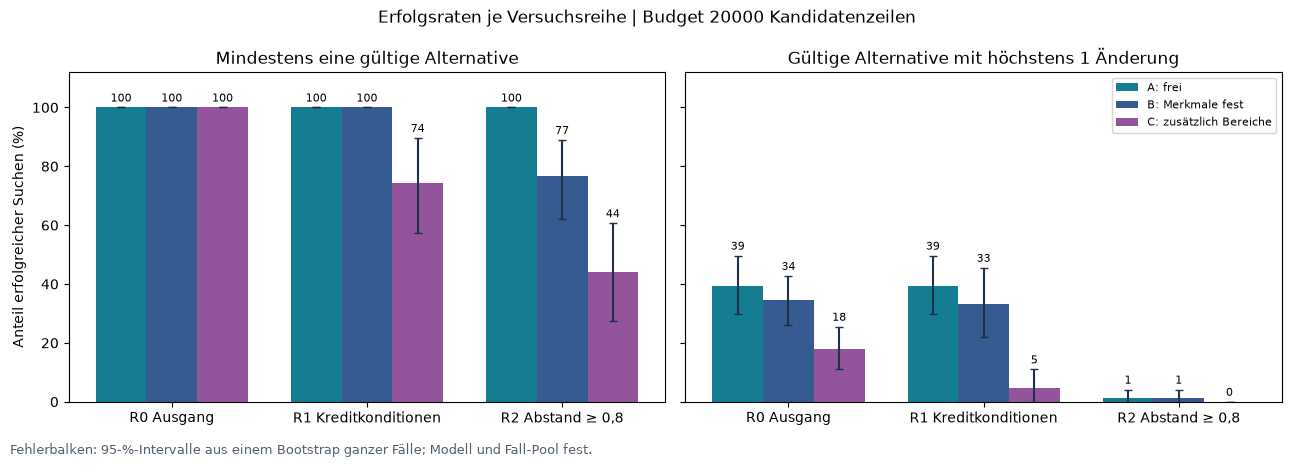

In [15]:
SUCCESS_METRICS = {"success": "Erfolgsrate", "success_one_change": "Erfolgsrate_1_Aenderung"}
rng = np.random.default_rng(BOOTSTRAP_SEED)
tables, difference_rows = [], []

for experiment in EXPERIMENT_IDS:
    runs = results.loc[results["experiment"] == experiment]
    n_cases = runs["case_id"].nunique()
    boot_indices = rng.integers(0, n_cases, size=(BOOTSTRAP_REPETITIONS, n_cases))
    table = runs.groupby("variant").agg(
        Suchen=("success", "size"), Erfolge=("success", "sum"),
        Erfolgsrate=("success", "mean"),
        Erfolgsrate_1_Aenderung=("success_one_change", "mean"),
        Vollstaendig=("complete", "mean"),
        Mittlere_Aenderungszahl=("num_changes", "mean"),
        Mittlere_Distanz=("distance", "mean"),
        Mittlere_Modellzeilen=("model_rows", "mean"),
        Mittlere_Sekunden=("seconds", "mean"),
    ).reindex(VARIANTS)

    for column, metric in SUCCESS_METRICS.items():
        case_rates = (runs.groupby(["case_id", "variant"])[column].mean().unstack().reindex(columns=VARIANTS))
        boot_rates = case_rates.to_numpy()[boot_indices].mean(axis=1)
        lower, upper = np.quantile(boot_rates, [0.025, 0.975], axis=0)
        table[metric + "_CI95_unten"] = lower
        table[metric + "_CI95_oben"] = upper

        for j, variant in enumerate(VARIANTS[1:], start=1):
            diff = boot_rates[:, j] - boot_rates[:, 0]
            difference_rows.append({
                "Reihe": experiment, "Mass": metric, "Vergleich": variant + " minus A_frei",
                "Differenz_Prozentpunkte": 100 * (
                    case_rates[variant] - case_rates["A_frei"]).mean(),
                "CI95_unten": 100 * np.quantile(diff, 0.025),
                "CI95_oben": 100 * np.quantile(diff, 0.975),
            })

    tables.append(table.assign(Reihe=experiment).set_index("Reihe", append=True))
    
summary = pd.concat(tables).reorder_levels(["Reihe", "variant"])
differences = pd.DataFrame(difference_rows)
display(summary.round(3))
display(differences.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
bar_width = 0.26
for ax, metric, title in zip(axes, SUCCESS_METRICS.values(),
                           ["Mindestens eine gültige Alternative",
                            "Gültige Alternative mit höchstens 1 Änderung"]):
    
    for j, variant in enumerate(VARIANTS):
        values = summary.xs(variant, level="variant").reindex(EXPERIMENT_IDS)
        x = np.arange(len(EXPERIMENT_IDS)) + (j - 1) * bar_width
        rates = values[metric].to_numpy() * 100
        upper = values[metric + "_CI95_oben"].to_numpy() * 100
        ax.bar(x, rates, width=bar_width, color=COLORS[variant], label=VARIANT_NAMES[variant])
        ax.errorbar(x, rates, yerr=[np.maximum(0, rates - values[metric + "_CI95_unten"].to_numpy() * 100), np.maximum(0, upper - rates)], fmt="none", ecolor="#20304a", capsize=3)

        for xi, value, up in zip(x, rates, upper):
            ax.text(xi, min(max(value, up) + 2, 106), f"{value:.0f}", ha="center", fontsize=8)

    ax.set_xticks(range(len(EXPERIMENT_IDS)), [EXPERIMENTS[r]["short"] for r in EXPERIMENT_IDS])
    ax.set(title=title, ylim=(0, 112))

axes[0].set_ylabel("Anteil erfolgreicher Suchen (%)")
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle(f"Erfolgsraten je Versuchsreihe | Budget {CANDIDATE_BUDGET} Kandidatenzeilen", fontsize=12)
fig.text(0.01, -0.03, "Fehlerbalken: 95-%-Intervalle aus einem Bootstrap ganzer Fälle; Modell und Fall-Pool fest.", fontsize=9, color="#506070")
fig.tight_layout()
fig.savefig(RESULTS_FOLDER / "03_erfolgsraten.png", bbox_inches="tight")
plt.show()

#### Hängen Misserfolge vom Fall oder vom Seed ab?

Die erste Tabelle zählt je Bedingung, wie viele der Fälle mit 0, 1, … 5 Seeds erfolgreich waren. Die zweite zeigt, wie knapp die nie erfolgreichen Fälle ursprünglich als bad eingestuft wurden.

In [16]:
successful_seeds = results.groupby(["experiment", "variant", "case_id"])["success"].sum()
seed_table = (successful_seeds.groupby(["experiment", "variant"]).value_counts().unstack(fill_value=0).reindex(index=pd.MultiIndex.from_product([EXPERIMENT_IDS, VARIANTS], names=["experiment", "variant"]), columns=range(len(SEARCH_SEEDS) + 1), fill_value=0))
display(seed_table.rename_axis(columns="Anzahl Fälle mit so vielen erfolgreichen Seeds"))

never_successful = successful_seeds[successful_seeds == 0].reset_index()
never_successful["p_bad"] = start_p_bad.loc[never_successful["case_id"]].to_numpy()
display(never_successful.groupby(["experiment", "variant"])["p_bad"].agg(Faelle="size", Mittleres_Ausgangs_p_bad="mean").round(3))
print(f"Zum Vergleich: mittleres Ausgangs-p(bad) aller ausgewählten Fälle {start_p_bad.mean():.3f}.")

Anzahl Fälle mit so vielen erfolgreichen Seeds   0  1  2  3  4   5
experiment       variant                                          
R0_ausgang       A_frei                          0  0  0  0  0  29
                 B_fest                          0  0  0  0  0  29
                 C_fest_bereich                  0  0  0  0  0  29
R1_beeinflussbar A_frei                          0  0  0  0  0  29
                 B_fest                          0  0  0  0  0  29
                 C_fest_bereich                  7  0  0  1  0  21
R2_abstand       A_frei                          0  0  0  0  0  29
                 B_fest                          4  1  2  0  4  18
                 C_fest_bereich                 14  0  2  1  3   9

Faelle  Mittleres_Ausgangs_p_bad
experiment       variant                                         
R1_beeinflussbar C_fest_bereich       7                     0.642
R2_abstand       B_fest               4                     0.633
                 C_fest_bereich      14                     0.589

Zum Vergleich: mittleres Ausgangs-p(bad) aller ausgewählten Fälle 0.574.


**Beobachtung:** In R0 sind alle 435 Suchen erfolgreich; nur das Zusatzmaß „höchstens 1 Änderung“ unterscheidet die Bedingungen (A 39,3 %, B 34,5 %, C 17,9 %). In R1 und R2 sinkt auch die Erfolgsrate, am stärksten in C (R1 74,5 %, R2 44,1 %). Die mittleren Modellzeilen in der ersten Tabelle zeigen, warum R0 nicht unterscheidet: Jede R0-Suche endet nach der zweiten Runde, dem frühestmöglichen Zeitpunkt (konstant 2.004 bzw. 2.504 Zeilen); das Budget von 20.000 Zeilen wird nie ausgeschöpft. Misserfolge hängen überwiegend am Fall, nicht am Seed: In R1 C scheitern 7 Fälle bei allen 5 Seeds, 21 Fälle sind immer erfolgreich. Die nie erfolgreichen Fälle waren im Mittel deutlicher als bad eingestuft als der Durchschnitt.

### 14. Änderungsumfang fair vergleichen

Die reine Mittelwerttabelle oben beschreibt nur erfolgreiche Suchen der jeweiligen Variante. Bei unterschiedlichen Erfolgsraten könnten dabei unterschiedlich schwierige Fälle verglichen werden.

Deshalb folgt ein gepaarter Vergleich auf genau den Fall-Seed-Kombinationen, für die innerhalb einer Versuchsreihe **alle drei Bedingungen** erfolgreich waren. Bei wenigen gemeinsamen Erfolgen bleibt diese Auswertung entsprechend eingeschränkt. Die gepaarten Werte werden je Fall über seine verfügbaren gemeinsamen Seeds gemittelt.

R0: Ausgangsdesign: gemeinsam erfolgreiche Fall-Seed-Paare 145 von 145.
R1: nur Kreditkonditionen veränderbar: gemeinsam erfolgreiche Fall-Seed-Paare 108 von 145.
R2: Sicherheitsabstand p(good) ≥ 0,8: gemeinsam erfolgreiche Fall-Seed-Paare 62 von 145.


num_changes             distance              
                                       mean median  max     mean median    max
experiment       variant                                                      
R0_ausgang       A_frei               1.607    2.0  2.0    0.054  0.054  0.100
                 B_fest               1.655    2.0  2.0    0.056  0.059  0.100
                 C_fest_bereich       1.821    2.0  2.0    0.062  0.053  0.100
R1_beeinflussbar A_frei               1.639    2.0  2.0    0.055  0.054  0.100
                 B_fest               1.741    2.0  3.0    0.039  0.036  0.103
                 C_fest_bereich       2.130    2.0  5.0    0.046  0.050  0.142
R2_abstand       A_frei               3.032    3.0  6.0    0.118  0.114  0.222
                 B_fest               3.419    3.0  9.0    0.133  0.118  0.349
                 C_fest_bereich       4.194    4.0  9.0    0.164  0.154  0.350

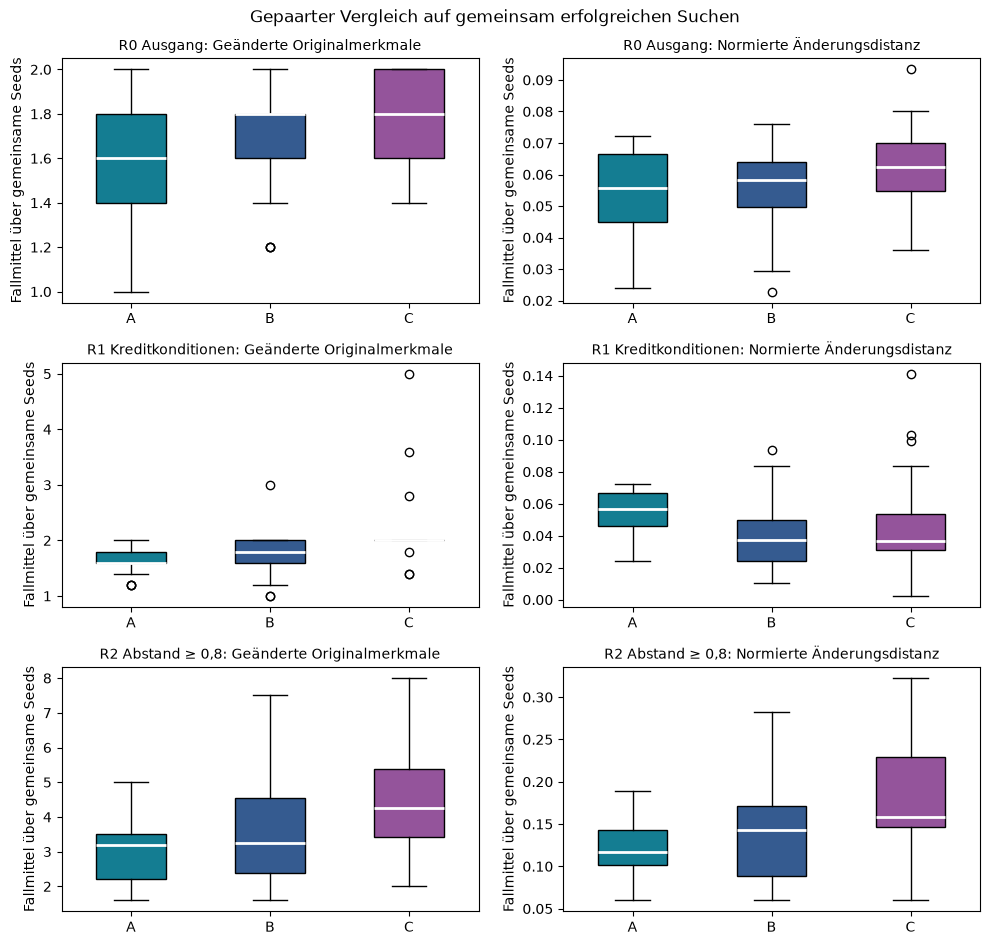

In [17]:
common_parts, common_counts = [], {}

for experiment in EXPERIMENT_IDS:
    runs = results.loc[results["experiment"] == experiment]
    success_matrix = runs.pivot(index=["case_id", "seed"], columns="variant", values="success").reindex(columns=VARIANTS)
    keys = success_matrix.index[success_matrix.eq(1).all(axis=1)]
    common_counts[experiment] = len(keys)
    run_index = pd.MultiIndex.from_frame(runs[["case_id", "seed"]])
    common_parts.append(runs.loc[run_index.isin(keys)])
    print(f"{EXPERIMENTS[experiment]['name']}: gemeinsam erfolgreiche Fall-Seed-Paare {len(keys)} von {len(success_matrix)}.")

common_successes = pd.concat(common_parts, ignore_index=True)

if len(common_successes):
    row_index = pd.MultiIndex.from_product([EXPERIMENT_IDS, VARIANTS], names=["experiment", "variant"])
    display(common_successes.groupby(["experiment", "variant"])[["num_changes", "distance"]].agg(["mean", "median", "max"]).reindex(row_index).round(3))
    common_means = common_successes.groupby(["experiment", "case_id", "variant"])[["num_changes", "distance"]].mean().reset_index()
    fig, axes = plt.subplots(len(EXPERIMENT_IDS), 2, figsize=(10, 3.2 * len(EXPERIMENT_IDS)), squeeze=False)

    for axes_row, experiment in zip(axes, EXPERIMENT_IDS):
        subset = common_means.loc[common_means["experiment"] == experiment]

        for a, metric, title in zip(
            axes_row, ["num_changes", "distance"],
            ["Geänderte Originalmerkmale", "Normierte Änderungsdistanz"]
        ):
            if subset.empty:
                a.set_axis_off()
                a.text(0.5, 0.5, "kein gemeinsamer Erfolg", ha="center", transform=a.transAxes)
                continue

            data = [subset.loc[subset["variant"] == v, metric].to_numpy() for v in VARIANTS]
            box = a.boxplot(data, patch_artist=True, widths=0.5, medianprops={"color": "white", "linewidth": 2})
            
            for patch, variant in zip(box["boxes"], VARIANTS):
                patch.set_facecolor(COLORS[variant])

            a.set_xticks([1, 2, 3], ["A", "B", "C"])
            a.set_title(f"{EXPERIMENTS[experiment]['short']}: {title}", fontsize=10)
            a.set_ylabel("Fallmittel über gemeinsame Seeds")
            
    fig.suptitle("Gepaarter Vergleich auf gemeinsam erfolgreichen Suchen", fontsize=12)
    fig.tight_layout()
    fig.savefig(RESULTS_FOLDER / "04_gepaarter_aenderungsumfang.png")
    plt.show()
else:
    print("Kein gemeinsamer Erfolg in einer Versuchsreihe; kein gepaarter Umfangsvergleich.")

**Beobachtung:** Auf den gemeinsam erfolgreichen Suchen ändern die Alternativen in jeder Reihe von A nach C im Mittel mehr Merkmale (R0 1,61 → 1,82; R1 1,64 → 2,13; R2 3,03 → 4,19). Der Sicherheitsabstand in R2 verdoppelt den Änderungsumfang ungefähr. In R0 ändert keine Alternative mehr als zwei Merkmale: Die Zufallssuche ersetzt je Runde ein weiteres Merkmal und endet dort immer nach zwei Runden. Die Distanz ist in R1 B und C kleiner als in A, obwohl mehr Merkmale geändert werden, weil dort nur numerische Kreditkonditionen geändert werden; sie zählen in der Distanz weniger als ein Kategoriewechsel (1/20 = 0,05).

### 15. Welche Merkmale ändern sich?

Die folgende Karte zeigt für die ausgewählten besten CFs erfolgreicher Suchen, wie häufig ein Originalmerkmal verändert wird. Die Nenner werden je Versuchsreihe und Variante ausgewiesen. Feste Merkmale müssen in B und C stets 0 % haben. Die Karte beschreibt die gefundenen Erklärungen und ist keine kausale Merkmalswichtigkeit des realen Kreditrisikos.

variant,A_frei,B_fest,C_fest_bereich
Erfolgreiche Suchen,,,
R0_ausgang,145,145,145
R1_beeinflussbar,145,145,108
R2_abstand,145,111,64


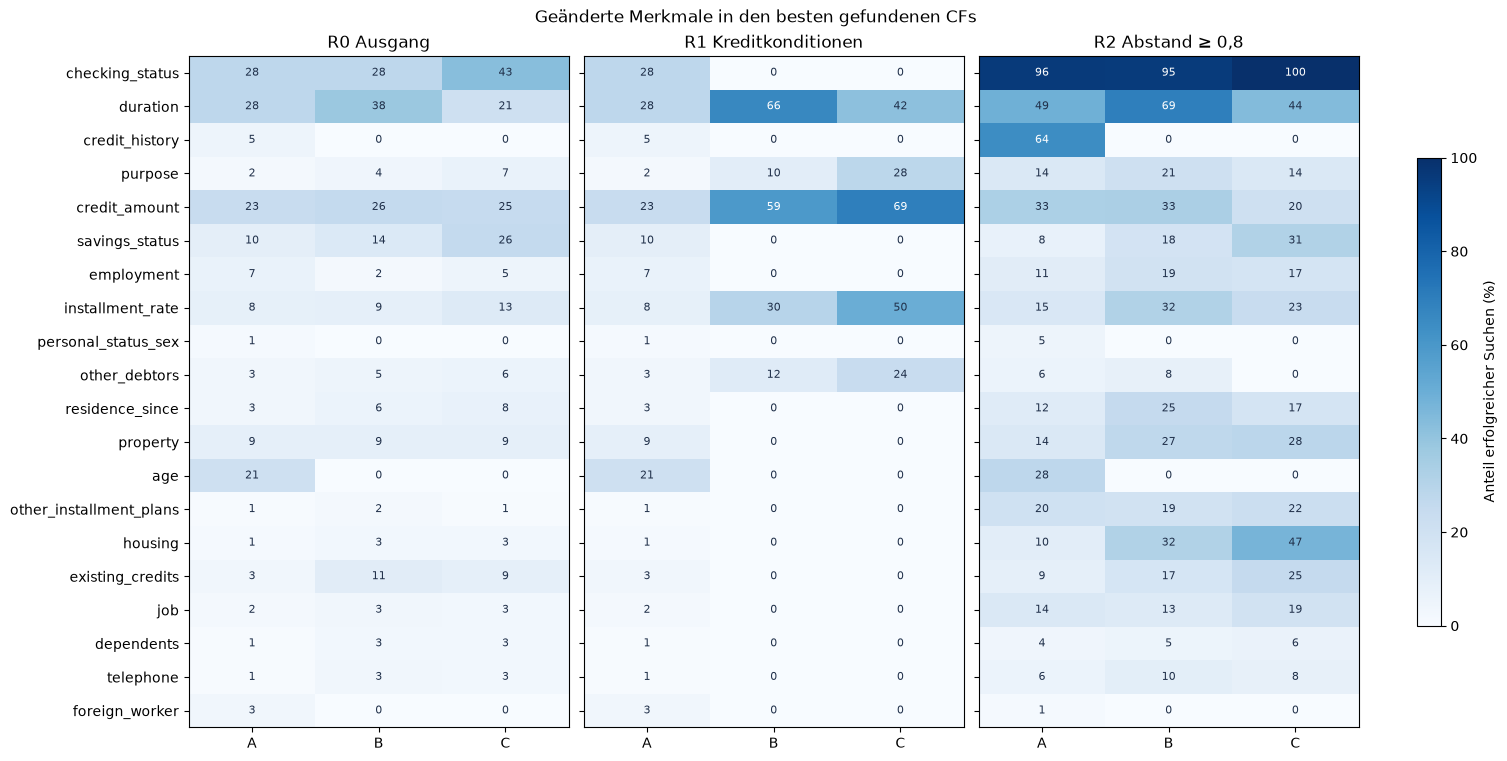

In [18]:
best_entries = []

for _, run in results.loc[results["success"] == 1].iterrows():
    matching = counterfactuals.loc[
        (counterfactuals["experiment"] == run["experiment"]) &
        (counterfactuals["case_id"] == run["case_id"]) &
        (counterfactuals["seed"] == run["seed"]) &
        (counterfactuals["variant"] == run["variant"]) &
        (counterfactuals["cf_number"] == run["best_cf_number"])
    ]

    best = matching.iloc[0]
    changed = set(str(best["changed_features"]).split("|"))
    best_entries.append({
        "experiment": run["experiment"], "case_id": int(run["case_id"]),
        "seed": int(run["seed"]), "variant": run["variant"],
        **{m: int(m in changed) for m in FEATURES},
    })

best_changes = pd.DataFrame(best_entries)

if len(best_changes):
    display(best_changes.groupby(["experiment", "variant"]).size().unstack("variant").reindex(index=EXPERIMENT_IDS, columns=VARIANTS).fillna(0).astype(int).rename_axis(index="Erfolgreiche Suchen"))
    fig, axes = plt.subplots(1, len(EXPERIMENT_IDS), figsize=(15, 7.5), sharey=True, layout="constrained")
    for ax, experiment in zip(axes, EXPERIMENT_IDS):
        frequencies = (best_changes.loc[best_changes["experiment"] == experiment].groupby("variant")[FEATURES].mean().reindex(VARIANTS) * 100)
        im = ax.imshow(frequencies.T, vmin=0, vmax=100, cmap="Blues", aspect="auto")
        ax.set_xticks(range(3), ["A", "B", "C"])
        ax.set_yticks(range(len(FEATURES)), FEATURES)

        for i in range(len(FEATURES)):
            for j in range(3):
                value = frequencies.iloc[j, i]
                if pd.notna(value):
                    ax.text(j, i, f"{value:.0f}", ha="center", va="center", color="white" if value > 55 else "#20304a", fontsize=8)

        ax.set_title(EXPERIMENTS[experiment]["short"])
        
    fig.suptitle("Geänderte Merkmale in den besten gefundenen CFs", fontsize=12)
    fig.colorbar(im, ax=axes, label="Anteil erfolgreicher Suchen (%)", fraction=0.02)
    fig.savefig(RESULTS_FOLDER / "05_geaenderte_merkmale.png")
    plt.show()

In [19]:
best_cfs = results.loc[results["success"] == 1, ["experiment", "case_id", "seed", "variant", "best_cf_number"]].merge(counterfactuals, left_on=["experiment", "case_id", "seed", "variant", "best_cf_number"],  right_on=["experiment", "case_id", "seed", "variant", "cf_number"])

status_changed = best_cfs["changed_features"].str.split("|").apply(lambda changed: "checking_status" in changed)
display(pd.crosstab([best_cfs.loc[status_changed, "experiment"], best_cfs.loc[status_changed, "variant"]], best_cfs.loc[status_changed, "checking_status"]).rename_axis(columns="Neuer checking_status (A14 = kein Girokonto)"))

start_values = X_test.loc[best_cfs["case_id"], ["duration", "credit_amount"]].to_numpy(dtype=float)
new_values = best_cfs[["duration", "credit_amount"]].to_numpy(dtype=float)
decreased = pd.DataFrame(np.where(new_values == start_values, np.nan, (new_values < start_values) * 100.0), columns=["duration", "credit_amount"])
display(decreased.groupby([best_cfs["experiment"], best_cfs["variant"]]).mean().round(0).rename(columns=lambda m: f"{m}: Anteil Senkungen an allen Änderungen (%)"))

Neuer checking_status (A14 = kein Girokonto)  A11  A12  A13  A14
experiment       variant                                        
R0_ausgang       A_frei                         0   13    9   18
                 B_fest                         1    8   12   19
                 C_fest_bereich                 0    9   13   40
R1_beeinflussbar A_frei                         0   13    9   18
R2_abstand       A_frei                         0    0    0  139
                 B_fest                         0    1    2  103
                 C_fest_bereich                 0    0    0   64

duration: Anteil Senkungen an allen Änderungen (%)  \
experiment       variant                                                              
R0_ausgang       A_frei                                                       98.0    
                 B_fest                                                       93.0    
                 C_fest_bereich                                               63.0    
R1_beeinflussbar A_frei                                                       98.0    
                 B_fest                                                       98.0    
                 C_fest_bereich                                               98.0    
R2_abstand       A_frei                                                       97.0    
                 B_fest                                                       97.0    
                 C_fest_bereich                                               89.0    

                                 credit_amount: Anteil Senkungen an allen Änderungen (%)  
experiment       variant                                                                  
R0_ausgang       A_frei                                                       62.0        
                 B_fest                                                       62.0        
                 C_fest_bereich                                               61.0        
R1_beeinflussbar A_frei                                                       62.0        
                 B_fest                                                       60.0        
                 C_fest_bereich                                               49.0        
R2_abstand       A_frei                                                       90.0        
                 B_fest                                                       97.0        
                 C_fest_bereich                                               62.0

**Beobachtung:** In A ändern die besten Alternativen am häufigsten Kontostatus, Laufzeit und Kreditbetrag; das Alter ändert sich in 21 % der Fälle, was B ausschließt. In R1 bleiben nur die Kreditkonditionen, dort dominieren Laufzeit und Betrag. Für p(good) ≥ 0,8 (R2) wird fast immer der Kontostatus geändert, und zwar nahezu immer auf A14 „kein Girokonto“. Die Laufzeit wird meist verkürzt, der Kreditbetrag in R0 und R1 aber in rund 40 bis 50 % der Änderungen erhöht. Die Alternativen folgen also dem gelernten Modell und nicht einer fachlich plausiblen Richtung.

### 16. Ein Testbeispiel über alle Bedingungen nachvollziehen

Es wird der erste vorab ausgewählte Testfall in allen drei Versuchsreihen angezeigt, auch wenn eine Bedingung für ihn keine Alternative findet. Dadurch wird kein besonders anschaulicher Erfolg nachträglich herausgepickt.

In [20]:
example_id = int(selection.index[0])
example_seed = SEARCH_SEEDS[0]
original = selection.loc[example_id]

display(pd.DataFrame({
    "Merkmal": ["case_id", "Bekannte Klasse", "Modellvorhersage"],
    "Wert": [str(example_id), CLASS_NAMES[int(y_test.loc[example_id])],
             CLASS_NAMES[1]],
}))

comparison_rows = []

for experiment in EXPERIMENT_IDS:
    for variant in VARIANTS:
        run = results.loc[
            (results["experiment"] == experiment) &
            (results["case_id"] == example_id) &
            (results["seed"] == example_seed) &
            (results["variant"] == variant)
        ].iloc[0]

        if not run["success"]:
            comparison_rows.append({
                "Reihe": experiment, "Variante": variant, "Merkmal": "Keine gültige Alternative",
                "Ausgangswert": "", "Alternative": run["status"],
            })
            continue

        best = counterfactuals.loc[
            (counterfactuals["experiment"] == experiment) &
            (counterfactuals["case_id"] == example_id) &
            (counterfactuals["seed"] == example_seed) &
            (counterfactuals["variant"] == variant) &
            (counterfactuals["cf_number"] == run["best_cf_number"])
        ].iloc[0]

        for m in best["changed_features"].split("|"):
            if m:
                comparison_rows.append({
                    "Reihe": experiment, "Variante": variant, "Merkmal": m,
                    "Ausgangswert": original[m], "Alternative": best[m],
                })
                
example_table = pd.DataFrame(comparison_rows)
display(example_table)

,Merkmal,Wert
0,case_id,11
1,Bekannte Klasse,bad
2,Modellvorhersage,bad


,Reihe,Variante,Merkmal,Ausgangswert,Alternative
0,R0_ausgang,A_frei,checking_status,A11,A14
1,R0_ausgang,A_frei,credit_amount,4308,2845
2,R0_ausgang,B_fest,duration,48,4
3,R0_ausgang,B_fest,job,A173,A172
4,R0_ausgang,C_fest_bereich,checking_status,A11,A14
5,R0_ausgang,C_fest_bereich,duration,48,55
6,R1_beeinflussbar,A_frei,checking_status,A11,A14
7,R1_beeinflussbar,A_frei,credit_amount,4308,2845
8,R1_beeinflussbar,B_fest,duration,48,6
9,R1_beeinflussbar,B_fest,credit_amount,4308,5691


**Beobachtung:** Für diesen Fall (Laufzeit 48 Monate, Kreditbetrag 4308, Kontostatus A11 „< 0 DM“, 24 Jahre) reichen in R0 zwei Änderungen. Die neuen Werte sind Zufallsziehungen aus dem erlaubten Bereich und können extrem sein: In B sinkt die Laufzeit von 48 auf 4 Monate, zusammen mit einem Wechsel von Fachkraft zu ungelernter Tätigkeit (A173 → A172). Die Bereichsgrenze in C hält die Werte nahe am Ausgangsfall, die Laufzeit steigt dort sogar auf 55 Monate. Mit Sicherheitsabstand (R2) werden fünf bis acht Merkmale geändert; in R2 C findet die Suche für diesen Seed keine Alternative.

### 17. Ergebnisse exportieren und reproduzierbar festhalten

Die CSV-Dateien enthalten alle Versuche, auch erfolglose. Die Konfiguration enthält Datenquelle, Versionen, Testfall-IDs, Suchseeds und die Regeln. Die Zeitmessung hängt vom jeweiligen Rechner ab. Für den Hauptvergleich werden deshalb vor allem Erfolg, Änderungen und gezählte Modellzeilen genutzt.

Die folgende Ergebniseinordnung wird aus den tatsächlich berechneten Werten zusammengesetzt; es werden keine erwarteten Befunde als Messwerte ausgegeben.

In [21]:
config = {
    "data_source": f"{DATA_FOLDER.name}/{DATA_FILE.name}",
    "python": platform.python_version(), "packages": {package: metadata.version(package) for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "dice-ml"]},
    "split_seed": SPLIT_SEED, "random_forest_seed": RANDOM_FOREST_SEED,
    "case_selection": "alle als bad / 1 vorhergesagten Testfälle",
    "search_seeds": SEARCH_SEEDS, "selected_cases": [int(i) for i in selection.index],
    "n_estimators": NUM_TREES, "max_depth": 8, "min_samples_leaf": 3,
    "target_class": TARGET_CLASS, "requested_cfs": NUM_CFS,
    "candidate_budget": CANDIDATE_BUDGET,
    "model_row_limit": MODEL_ROW_LIMIT,
    "experiments": EXPERIMENTS, "loan_terms_r1": LOAN_TERMS,
    "secondary_metric": "Erfolg mit höchstens einem geänderten Merkmal",
    "range_limited_features": ["credit_amount", "duration"],
    "relative_limit": RELATIVE_LIMIT, "posthoc_sparsity_param": 0,
    "bootstrap_repetitions": BOOTSTRAP_REPETITIONS,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "pipeline": "OneHotEncoder für Kategorien; Zahlen unverändert; RandomForest",
    "search_method": "DiCE random; Stichprobengröße nach Zahl variabler Merkmale",
    "budget_definition": "Gezählte Eingabezeilen der DiCE-Modellaufrufe; Prüfungen separat",
}

export_files = {
    "suchlaeufe.csv": results, "counterfactuals.csv": counterfactuals,
    "zusammenfassung.csv": summary.reset_index(),
    "gepaarte_erfolgsdifferenzen.csv": differences,
    "gemeinsame_erfolge.csv": common_successes,
    "modellvergleich.csv": model_comparison,
    "kreuzvalidierung.csv": cv_table,
    "merkmalslexikon.csv": feature_glossary,
    "testbeispiel.csv": example_table,
}

for name, table in export_files.items():
    table.to_csv(RESULTS_FOLDER / name, index=False, encoding="utf-8-sig")
X_train.assign(risk=y_train).to_csv(RESULTS_FOLDER / "train.csv", index=True)
X_test.assign(risk=y_test).to_csv(RESULTS_FOLDER / "test.csv", index=True)
(RESULTS_FOLDER / "konfiguration.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

def format_percent(value):
    return f"{value * 100:.1f} %".replace(".", ",")

rf_metrics = model_comparison.loc[model_comparison["Modell"] == "Random Forest"].iloc[0]
report_lines = [
    f"{len(EXPERIMENT_IDS)} Versuchsreihen, {len(selection)} Testfälle, {len(SEARCH_SEEDS)} "
    f"Suchseeds und {len(VARIANTS)} Bedingungen ergeben {len(results)} "
    f"protokollierte Suchen mit festem Budget von {CANDIDATE_BUDGET} "
    "Kandidatenzeilen je Suche.",
    f"Der Random Forest erreicht im zurückgehaltenen Testset eine Accuracy von "
    f"{format_percent(rf_metrics['Accuracy'])} und eine Balanced Accuracy von "
    f"{format_percent(rf_metrics['Balanced Accuracy'])}.",
    f"Der Recall für bad / 1 beträgt {format_percent(rf_metrics['Recall bad / 1'])}. "
    "Dieser Wert zeigt separat, welcher Anteil der bekannten ungünstigen Fälle "
    "erkannt wird. Eine gültige gegenfaktische Erklärung verbessert diese "
    "Klassifikationsleistung nicht automatisch.",
]

for experiment in EXPERIMENT_IDS:
    parts = []

    for variant in VARIANTS:
        row = summary.loc[(experiment, variant)]
        parts.append(f"{VARIANT_NAMES[variant]} {format_percent(row['Erfolgsrate'])} (mit 1 Änderung: {format_percent(row['Erfolgsrate_1_Aenderung'])})")
    report_lines.append(f"**{EXPERIMENTS[experiment]['name']}:** Erfolgsrate " + "; ".join(parts) + f". Gemeinsam erfolgreiche Fall-Seed-Paare: {common_counts[experiment]}.")

report = "\n\n".join(report_lines)
display(Markdown(report))
(RESULTS_FOLDER / "ergebniseinordnung.md").write_text(report, encoding="utf-8")
print("Exportdateien liegen im Unterordner ergebnisse_dice des Ausführungsordners.")

3 Versuchsreihen, 29 Testfälle, 5 Suchseeds und 3 Bedingungen ergeben 1305 protokollierte Suchen mit festem Budget von 20000 Kandidatenzeilen je Suche.

Der Random Forest erreicht im zurückgehaltenen Testset eine Accuracy von 77,5 % und eine Balanced Accuracy von 65,8 %.

Der Recall für bad / 1 beträgt 36,7 %. Dieser Wert zeigt separat, welcher Anteil der bekannten ungünstigen Fälle erkannt wird. Eine gültige gegenfaktische Erklärung verbessert diese Klassifikationsleistung nicht automatisch.

**R0: Ausgangsdesign:** Erfolgsrate A: frei 100,0 % (mit 1 Änderung: 39,3 %); B: Merkmale fest 100,0 % (mit 1 Änderung: 34,5 %); C: zusätzlich Bereiche 100,0 % (mit 1 Änderung: 17,9 %). Gemeinsam erfolgreiche Fall-Seed-Paare: 145.

**R1: nur Kreditkonditionen veränderbar:** Erfolgsrate A: frei 100,0 % (mit 1 Änderung: 39,3 %); B: Merkmale fest 100,0 % (mit 1 Änderung: 33,1 %); C: zusätzlich Bereiche 74,5 % (mit 1 Änderung: 4,8 %). Gemeinsam erfolgreiche Fall-Seed-Paare: 108.

**R2: Sicherheitsabstand p(good) ≥ 0,8:** Erfolgsrate A: frei 100,0 % (mit 1 Änderung: 1,4 %); B: Merkmale fest 76,6 % (mit 1 Änderung: 1,4 %); C: zusätzlich Bereiche 44,1 % (mit 1 Änderung: 0,0 %). Gemeinsam erfolgreiche Fall-Seed-Paare: 62.

Exportdateien liegen im Unterordner ergebnisse_dice des Ausführungsordners.


### 18. Diskussion und Fazit

Die Zahlen beziehen sich auf den gespeicherten Lauf. Wegen fester Seeds und Paketversionen liefert ein Neulauf dieselben Werte; nur die Laufzeiten ändern sich.

#### Antwort auf die Forschungsfrage

Festgehaltene Merkmale und begrenzte Wertebereiche erhöhen in allen drei Versuchsreihen den Änderungsumfang. Die Erfolgsrate senken sie nur, wenn die Suche nicht ohnehin leicht ist.

- **Festgehaltene Merkmale (B gegenüber A):** Im angemeldeten Design R0 bleibt die Erfolgsrate bei 100 %. Erfolg mit höchstens einer Änderung sinkt nur leicht von 39,3 % auf 34,5 %; das 95-%-Intervall der Differenz (−12,4 bis +2,8 Prozentpunkte) schließt 0 ein. Die vier festen Personenmerkmale werden in A selten gebraucht, nur das Alter ändert sich dort in 21 % der besten Alternativen. Erst mit Sicherheitsabstand (R2) sinkt die Erfolgsrate auf 76,6 % (−23,4 Prozentpunkte, Intervall −37,9 bis −11,0).
- **Begrenzte Wertebereiche (C gegenüber A):** Sie wirken stärker, weil Laufzeit und Kreditbetrag neben dem Kontostatus die am häufigsten genutzten Hebel sind. In R0 halbiert sich Erfolg mit höchstens einer Änderung (17,9 % statt 39,3 %; −21,4 Prozentpunkte, Intervall −31,7 bis −10,3). Sind nur Kreditkonditionen veränderbar (R1), sinkt die Erfolgsrate auf 74,5 % (−25,5; −42,8 bis −10,3), mit Sicherheitsabstand (R2) auf 44,1 % (−55,9; −72,4 bis −39,3).
- **Änderungsumfang:** Auf gemeinsam erfolgreichen Suchen steigt die mittlere Zahl geänderter Merkmale von A nach C in jeder Reihe (R0 1,61 → 1,82; R1 1,64 → 2,13; R2 3,03 → 4,19).

#### Reflexion: Warum das angemeldete Design nicht unterscheidet

In R0 sind alle Suchen in allen Bedingungen erfolgreich. Die primäre Metrik kann die Forschungsfrage dort also nicht beantworten. Drei Ursachen lassen sich im Notebook belegen:

1. **Die erklärten Fälle liegen knapp an der Grenze.** Der Forest sagt bad nur für 29 von 200 Testfällen voraus, und auch dann knapp (Ausgangs-p(bad) Median 0,57, Maximum 0,75; Abschnitt 9). Wenige Änderungen genügen, um unter 0,5 zu fallen. Das passt zum Modell, das mit einem Recall von 36,7 % bad nur selten vorhersagt.
2. **Die Suche endet sofort.** Jede R0-Suche endet nach der zweiten Runde, dem frühestmöglichen Zeitpunkt (Abschnitt 13). Das Budget wird nie ausgeschöpft; deshalb änderten auch kleinere Budgets im Vortest nichts.
3. **Es bleiben viele Hebel.** Auch mit festen Personenmerkmalen sind 16 Merkmale veränderbar, darunter Kontostatus und Ersparnisse. Sie bleiben in C frei, wenn Betrag und Laufzeit begrenzt sind.

R1 und R2 verschärfen gezielt die dritte und die erste Ursache: R1 nimmt Hebel weg, R2 verschiebt das Ziel weiter von der Grenze weg. Erst dadurch werden Unterschiede zwischen A, B und C in der Erfolgsrate sichtbar. Beide Reihen wurden aber erst nach dem ersten Lauf ergänzt; ihre Ergebnisse sind deshalb explorativ und keine vorab geplante Bestätigung.

#### Grenzen der Messung

- **Die Änderungszahl hängt vom Suchverfahren ab.** Die Zufallssuche ersetzt je Runde ein weiteres Merkmal. Endet sie nach zwei Runden, hat keine Alternative mehr als zwei Änderungen; in R0 gilt das für alle Suchen (Abschnitt 14). Die Änderungszahl misst daher auch, wie lange gesucht wurde, und ist keine minimale Änderung.
- **Die Distanz mischt Merkmalsarten.** Ein Kategoriewechsel zählt 0,05, eine numerische Änderung nur ihren Anteil an der Spannweite. Deshalb ist die Distanz in R1 B und C kleiner als in A, obwohl dort mehr Merkmale geändert werden.
- **Ein Misserfolg ist kein Unmöglichkeitsbeweis.** Misserfolge hängen überwiegend am Fall (Abschnitt 13); die nie erfolgreichen Fälle waren deutlicher als bad eingestuft. Die Zufallssuche probiert aber nur einen kleinen Teil des erlaubten Raums aus.
- **Gültig heißt nicht sinnvoll.** Für p(good) ≥ 0,8 setzen die Alternativen den Kontostatus fast immer auf A14 „kein Girokonto“ (Abschnitt 15). Das Modell hat aus den historischen Daten gelernt, dass Antragsteller ohne Girokonto selten als bad erfasst wurden; als Empfehlung wäre das unsinnig. Ebenso wird der Kreditbetrag in R0 und R1 oft erhöht, und im Testbeispiel sinkt die Laufzeit von 48 auf 4 Monate. Gegenfaktische Erklärungen beschreiben das Modell, keine kausalen Wirkungen in der realen Welt (Wachter et al. 2018); umsetzbare Empfehlungen bräuchten zusätzliche Regeln, etwa Richtungsvorgaben (Ustun et al. 2019).
- **Sucherfolg ist keine Modellgüte.** Eine Erfolgsrate von 100 % sagt nichts darüber aus, wie gut der Forest Kreditrisiken erkennt.

**Grenzen dieser Umsetzung:** historischer, kleiner Datensatz; ein Modell und ein Trainingssplit; ausgewählte Testfälle mit vorhergesagter Klasse 1; eine DiCE-Suchmethode; manuell definierte Beschränkungen; keine vollständige Prüfung von Abhängigkeiten zwischen allen Merkmalen. Das Vertrauen in das Modell selbst und die Qualität seiner gegenfaktischen Erklärungen sind unterschiedliche Untersuchungsgegenstände.

#### Fazit

Je mehr Merkmale festgehalten und je enger Wertebereiche gesetzt werden, desto seltener findet DiCE eine gültige Alternative und desto mehr Merkmale ändert eine gefundene Alternative. Begrenzte Wertebereiche für Betrag und Laufzeit wirken dabei stärker als das Festhalten persönlicher Merkmale. Auf die Erfolgsrate wirkt sich das aber nur aus, wenn die Aufgabe schwer genug ist. Für die knapp als bad eingestuften Fälle dieses Modells ist sie im angemeldeten Design zu leicht. Die Ergebnisse gelten für ein Modell, einen Split, 29 Fälle und eine Suchmethode.

#### Ausblick

- Andere DiCE-Suchverfahren (`genetic`, `kdtree`) vergleichen, um zu prüfen, ob Misserfolge an der Zufallssuche liegen.
- Richtungsvorgaben (zum Beispiel Kreditbetrag nur senken) und den Ausschluss unplausibler Kategorien wie „kein Girokonto“ ergänzen.
- Mehrere Trainingssplits und Modelle verwenden, um auch die Unsicherheit durch das Training zu erfassen.

### 19. Wissenschaftliche Quellen und technische Dokumentation

**Literatur**

- Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Efron, B. und Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. New York: Chapman & Hall.
- Gower, J. C. (1971). A General Coefficient of Similarity and Some of Its Properties. *Biometrics*, 27(4), 857–871. https://doi.org/10.2307/2528823
- Hofmann, H. (1994). Statlog (German Credit Data) [Datensatz]. UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77. Lizenz: CC BY 4.0. Dokumentation: https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data und lokal `statlog+german+credit+data/german.doc`.
- Mothilal, R. K., Sharma, A. und Tan, C. (2020). Explaining Machine Learning Classifiers through Diverse Counterfactual Explanations. In *Proceedings of the 2020 Conference on Fairness, Accountability, and Transparency (FAT\* '20)*, 607–617. https://doi.org/10.1145/3351095.3372850
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Upadhyay, S., Joshi, S. und Lakkaraju, H. (2021). Towards Robust and Reliable Algorithmic Recourse. In *Advances in Neural Information Processing Systems 34 (NeurIPS 2021)*. https://arxiv.org/abs/2102.13620
- Ustun, B., Spangher, A. und Liu, Y. (2019). Actionable Recourse in Linear Classification. In *Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT\* '19)*, 10–19. https://doi.org/10.1145/3287560.3287566
- Wachter, S., Mittelstadt, B. und Russell, C. (2018). Counterfactual Explanations without Opening the Black Box: Automated Decisions and the GDPR. *Harvard Journal of Law & Technology*, 31(2), 841–887. https://arxiv.org/abs/1711.00399

**Technische Dokumentation**

- DiCE-Beispiel für scikit-learn mit Zufallssuche, festen Merkmalen und Wertebereichen (DiCE 0.12): https://interpret.ml/DiCE/notebooks/DiCE_model_agnostic_CFs.html
- DiCE-Quellcode, Zufallssuche in `dice_ml/explainer_interfaces/dice_random.py`: https://github.com/interpretml/DiCE
- scikit-learn RandomForestClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- scikit-learn plot_tree: https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html
- scikit-learn zu Vorverarbeitung und Datenleckage: https://scikit-learn.org/stable/common_pitfalls.html

### 20. Erklärung zur Nutzung von KI-Werkzeugen

Im Projekt wurde das KI-Werkzeug Claude (Anthropic) unterstützend eingesetzt:

- **Recherche wissenschaftlicher Quellen:** Hinweise auf passende Literatur zu gegenfaktischen Erklärungen und Algorithmic Recourse.
- **Einzelne Code-Abschnitte:** Vorschläge für einzelne Codeteile wurden nachvollzogen, an das Projekt angepasst und durch Ausführen des Notebooks sowie die Qualitätskontrolle in Abschnitt 12 überprüft.